In [ ]:
# ==============================================================================
# Purpose:
#   B-cell CNA + gene-program interpretation (race effect; NHB vs NHW):
#     (1) Run CNA neighborhood association for race within each B subtype × disease state,
#     (2) Correlate per-cell neighborhood race coefficient (race_coef) with gene expression
#         using a fast Spearman implementation,
#     (3) Run preranked GSEA (Hallmark + ImmPort) on gene-wise rho,
#     (4) Generate Figure 7.2 panels:
#         - B UMAPs: subtype, race, and significant neighborhood race_coef
#         - GSEA summaries: multi-panel barh NES across subtypes/states + bubble plots
#           per disease state for selected ImmPort sets.
#
# Steps:
#   1) Configure plotting defaults (Nature Immunology-ish), vector-friendly Scanpy.
#   2) Load sample metadata (meta_pt.csv) and define race-stage categories.
#   3) Load full AnnData (ft_all.h5ad) and map sample-level covariates into dat.obs
#      using dataset_name.
#   4) Encode covariates:
#        - diabetes/obesity: 'Y'->1 else 0
#        - group: HRL->0, DCIS->1, BC->2
#        - race: NHW->0, NHB->1
#   5) Subset major compartment (celltype_major='B') and attach precomputed UMAP coords.
#      Create disease_state labels from encoded group.
#   6) For each (B subtype × disease_state):
#        - subset cells
#        - compute neighbors (required by CNA)
#        - build sample-level design matrix (samplem) with covariates
#        - add batch label from sample name prefix (Pool137 vs Pool138)
#        - run cna.tl.association with race as exposure (key_added='race_coef')
#        - correlate race_coef vs genes (fast_spearman_ann) -> rho
#        - prerank GSEA on rho for Hallmark and ImmPort; save CSVs
#   7) Repeat CNA + Spearman + GSEA for "all B cells" within each disease_state
#      (ignores subtype stratification).
#   8) Load precomputed CNA object overall_B.pkl to plot UMAP panels:
#        - B subtypes (ordered categorical + palette)
#        - race (NHW/NHB)
#        - neighborhood coefficient map (race_coef shown only if FDR<0.1; else gray)
#      Summarize subtype composition among significant +/− coefficients.
#   9) Aggregate per-(subtype × state × db) GSEA CSVs into a single table `out`
#      and reformat columns:
#        - Tag % parsed -> percent
#        - log_p = -log10(FDR q-val)
#        - Term cleaned (strip HALLMARK_ and uppercase)
#  10) Plot GSEA summaries:
#        - Barh NES panels for selected terms across subtypes/states (multi-panel figure)
#        - Bubble plots per disease state (NES vs pathway; size=Tag%; color=-log10 q)

# Header

In [1]:
from utils import *

In [2]:
import sys
sys.path.insert(0, '/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src')
import cna

In [3]:
import gseapy as gp
import scanpy as sc
from itertools import product
from matplotlib.patches import Patch
from textwrap import fill

In [4]:
os.chdir('../')

In [5]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [6]:
cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}

In [7]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from scipy import sparse
from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests

def fast_spearman_ann(adata, obs_key, genes=None, chunk_size=2000, eps=1e-12):
    """
    Fast Spearman correlation between a per-cell variable (obs_key)
    and expression of each gene in adata.
    Returns a DataFrame with columns: rho, pval, fdr.
    """
    if genes is None:
        genes = adata.var_names
    X = adata[:, genes].X
    n_cells, n_genes = X.shape

    # rank-transform the covariate
    c = pd.to_numeric(adata.obs[obs_key], errors='coerce').to_numpy()
    r_c = rankdata(c, method='average')
    r_c0 = r_c - r_c.mean()
    norm_rc0 = np.linalg.norm(r_c0) + eps

    rho = np.empty(n_genes, dtype=float)

    for start in range(0, n_genes, chunk_size):
        end = min(start + chunk_size, n_genes)
        Xi = X[:, start:end]

        if sparse.issparse(Xi):
            Xi = Xi.toarray()

        # rank each gene (column) across cells
        R = np.apply_along_axis(rankdata, 0, Xi, method='average')
        R0 = R - R.mean(axis=0, keepdims=True)
        denomX = np.linalg.norm(R0, axis=0) + eps

        # Pearson on ranks = Spearman
        rho[start:end] = (R0.T @ r_c0) / (norm_rc0 * denomX)

    # --- p-values (two-sided) via t-approximation ---
    df = n_cells - 2
    # Clamp |rho| to < 1 to avoid division by zero
    rho_clamped = np.clip(rho, -1 + 1e-15, 1 - 1e-15)
    t_stat = rho_clamped * np.sqrt(df / (1 - rho_clamped**2))
    pval = 2 * student_t.sf(np.abs(t_stat), df=df)

    # --- FDR (Benjamini–Hochberg) ---
    fdr = multipletests(pval, method='fdr_bh')[1]

    out = pd.DataFrame(
        {'rho': rho, 'pval': pval, 'fdr': fdr},
        index=pd.Index(genes, name='gene')
    )
    out.name = f'spearman_{obs_key}'
    return out

In [8]:
with open('data/Legends/celltypelevel3_palette.pkl','rb') as f:
    palette_all = pkl.load(f)

palette_all

{'Naive B': (0.843137, 0.0, 0.0),
 'Mature B': (0.54902, 0.235294, 1.0),
 'Memory B': (0.007843, 0.533333, 0.0),
 'Plasmablast': (0.0, 0.67451, 0.780392),
 'Naive CD4T': (0.596078, 1.0, 0.0),
 'Central Memory CD4T': (1.0, 0.498039, 0.819608),
 'Effector Memory CD4T': (0.423529, 0.0, 0.309804),
 'Cytotoxic CD4T': (1.0, 0.647059, 0.188235),
 'Treg': (0.345098, 0.231373, 0.0),
 'Naive CD8T': (0.0, 0.341176, 0.34902),
 'Central Memory CD8T': (0.0, 0.0, 0.866667),
 'Effector Memory CD8T': (0.0, 0.992157, 0.811765),
 'Double Negative T': (0.631373, 0.458824, 0.415686),
 'γδ T': (0.737255, 0.717647, 1.0),
 'MAIT': (0.584314, 0.709804, 0.470588),
 'cDC1': (0.752941, 0.015686, 0.72549),
 'cDC2': (0.392157, 0.329412, 0.454902),
 'pDC': (0.47451, 0.0, 0.0),
 'Classical Monocyte': (0.027451, 0.454902, 0.847059),
 'Intermediate Monocyte': (0.996078, 0.960784, 0.564706),
 'Nonclassical Monocyte': (0.0, 0.294118, 0.0),
 'Cytotoxic Monocyte': (0.560784, 0.478431, 0.0),
 'CD56-dim NK': (1.0, 0.447059, 

# Load data

In [10]:
meta = pd.read_csv('data/01_meta/meta_pt.csv', index_col=0)
#meta.index = [x.replace('_','-') for x in meta.index]

meta['race-stage'] = meta['race'].astype(str) + '-' + meta['group'].astype(str)
meta = meta.drop(columns = ['race_stage'])


meta['race-stage'] = pd.Categorical(
    meta['race-stage'],
    categories=['NHW-HRL', 'NHW-DCIS', 'NHW-BC','NHB-HRL', 'NHB-DCIS', 'NHB-BC'],
    ordered=True
    )

meta

,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
sampleid,,,,,,,,,
9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,Y,NHW-DCIS
30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,Y,NHB-DCIS
119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,Y,NHB-DCIS
28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [11]:
dat = sc.read_h5ad(
    'data/03_cleandata/ft_all.h5ad'
)

dat.obs

,nFeaturess_RNA,nFeaturess_RNA_by_counts,total_counts,total_counts_mt,pct_counts_mt,doublets_score,nCount_RNA,nFeature_RNA,percent.mt,predicted.celltype.l1.score,...,predicted.celltype.l3,mapping.score,RNA_snn_res.0.8,seurat_clusters,dataset_name,RNA_snn_res.0.1,S.Score,G2M.Score,Phase,celltype_level3
Pool137_10_AAACCTGAGACTCGGA-1,1095.0,1095,2669.0,80.0,2.997377,0.039230,2669.0,1095.0,2.997377,0.987477,...,CD4 TCM_1,0.827455,0,0,Pool137_10,0,-0.035611,-0.030749,G1,Naive CD4T
Pool137_10_AAACCTGAGATCTGCT-1,2474.0,2472,6188.0,178.0,2.876535,0.021953,6188.0,2472.0,2.876535,1.000000,...,CD16 Mono,0.740965,5,5,Pool137_10,5,0.004613,0.004461,S,Nonclassical Monocyte
Pool137_10_AAACCTGAGATTACCC-1,1436.0,1436,3504.0,100.0,2.853881,0.039230,3504.0,1436.0,2.853881,0.996618,...,CD8 Naive,0.874696,6,6,Pool137_10,6,0.027257,-0.066766,S,Naive CD8T
Pool137_10_AAACCTGAGCTGCGAA-1,1033.0,1033,2685.0,104.0,3.873371,0.053408,2685.0,1033.0,3.873371,0.990250,...,CD4 TCM_1,0.842401,0,0,Pool137_10,0,-0.049705,0.004598,G2M,Naive CD4T
Pool137_10_AAACCTGAGGACACCA-1,2518.0,2515,6370.0,189.0,2.967033,0.012493,6370.0,2515.0,2.967033,1.000000,...,CD16 Mono,0.836383,5,5,Pool137_10,5,0.003770,-0.014496,S,Nonclassical Monocyte
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pool138_9_TTTGTCATCCATGAAC-1,1309.0,1308,2604.0,43.0,1.651306,0.026204,2604.0,1308.0,1.651306,1.000000,...,CD14 Mono,0.925401,2,1,Pool138_9,1,0.128049,0.014490,S,Classical Monocyte
Pool138_9_TTTGTCATCCTAGGGC-1,1464.0,1464,3533.0,41.0,1.160487,0.105614,3533.0,1464.0,1.160487,1.000000,...,CD4 TCM_3,0.890462,5,0,Pool138_9,0,0.020027,-0.014519,S,Effector Memory CD4T
Pool138_9_TTTGTCATCGCACTCT-1,1310.0,1310,3125.0,56.0,1.792000,0.020296,3125.0,1310.0,1.792000,1.000000,...,CD4 TCM_1,0.842334,1,0,Pool138_9,0,-0.052514,-0.009035,G1,Naive CD4T
Pool138_9_TTTGTCATCTAACTGG-1,1774.0,1774,5072.0,107.0,2.109622,0.085158,5072.0,1774.0,2.109621,1.000000,...,CD4 TCM_1,0.824522,1,0,Pool138_9,0,-0.042068,0.002366,G2M,Naive CD4T


In [12]:
for col in ['age', 'race-stage', 'race', 'group', 'diabetes', 'obesity']:
    dat.obs[col] = dat.obs['dataset_name'].map(meta.set_index('dataset_name')[col])
    
for xcol in ['diabetes','obesity']:
    dat.obs[xcol] = [1 if x=='Y' else 0 for x in dat.obs[xcol]]

xcol = 'group'
dat.obs[xcol] = [0 if x=='HRL' else 1 if x=='DCIS' else 2 for x in dat.obs[xcol]]

xcol = 'race'
dat.obs[xcol] = [0 if x=='NHW' else 1 if x=='NHB' else None for x in dat.obs[xcol]]

dat.obs.columns

Index(['nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts',
       'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA',
       'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score',
       'predicted.celltype.l1', 'predicted.celltype.l2.score',
       'predicted.celltype.l2', 'predicted.celltype.l3.score',
       'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8',
       'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score',
       'G2M.Score', 'Phase', 'celltype_level3', 'age', 'race-stage', 'race',
       'group', 'diabetes', 'obesity'],
      dtype='object')

In [13]:
celltype_major = 'B'

In [14]:
d = dat[
    dat.obs['predicted.celltype.l1'] == celltype_major
]
d

View of AnnData object with n_obs × n_vars = 49158 × 27879
    obs: 'nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score', 'predicted.celltype.l1', 'predicted.celltype.l2.score', 'predicted.celltype.l2', 'predicted.celltype.l3.score', 'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8', 'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score', 'G2M.Score', 'Phase', 'celltype_level3', 'age', 'race-stage', 'race', 'group', 'diabetes', 'obesity'
    var: 'vf_vst_counts.Pool137_10_mean', 'vf_vst_counts.Pool137_10_variance', 'vf_vst_counts.Pool137_10_variance.expected', 'vf_vst_counts.Pool137_10_variance.standardized', 'vf_vst_counts.Pool137_10_variable', 'vf_vst_counts.Pool137_10_rank', 'vf_vst_counts.Pool137_11_mean', 'vf_vst_counts.Pool137_11_variance', 'vf_vst_counts.Pool137_11_variance.expected', 'vf_vst_counts.Pool137_11_variance.standa

In [15]:
umap = pd.read_csv(f"data/03_cleandata/ft_{celltype_major}_UmapCoords.csv",
                   index_col=2
                  ).loc[d.obs.index,:]

d.obsm['X_umap'] = umap.values

/tmp/ipykernel_3384108/3805644948.py:5: ImplicitModificationWarning: Setting element `.obsm['X_umap']` of view, initializing view as actual.
  d.obsm['X_umap'] = umap.values


# Calc

## Disease state

In [16]:
d.obs['disease_state'] = ['HRL' if x==0 else 'DCIS' if x==1 else 'BC' if x==2 else None for x in d.obs['group']]

Counter(d.obs['disease_state'])

Counter({'BC': 21625, 'HRL': 19797, 'DCIS': 7736})

In [17]:
for group in ['HRL','DCIS','BC']:
    
    d_sub = d[
    (d.obs['disease_state']==group)
    ]

    sc.pp.neighbors(d_sub)

    covars = ['race', 'age']
    for v in ['obesity', 'diabetes']:
        if v in d_sub.obs and d_sub.obs[v].dropna().nunique() > 1:
            covars.append(v)
            
    samplem = cna.ut.obs_to_sample(d_sub,                           # the dataset
                                   covars,     # the metadata columns to use
                                   'dataset_name')                        # the column of d.obs that contains sample IDs
    
    samplem['batch'] = ['Pool137' if x.startswith('Pool137') else 'Pool138' for x in samplem.index]
    
    
    res = cna.tl.association(
        d_sub,
        samplem.race, 
        'dataset_name',
        covs=samplem[[c for c in covars if c != 'race']],
        batches=samplem.batch,
        key_added='race_coef',
        return_full=True
    )


    res = fast_spearman_ann(d_sub, 
                        obs_key='race_coef', 
                        genes=d_sub.var_names, chunk_size=2000)

    gene_corr_df = pd.DataFrame(res)
    
    pre_res1 = gp.prerank(rnk=gene_corr_df[['rho']], # or rnk = rnk,
                         gene_sets='data/11_genesets/h.all.v2024.1.Hs.symbols.gmt',
                         threads=1,
                         min_size=5,
                         max_size=1000,
                         permutation_num=1000, # reduce number to speed up testing
                         outdir=None, # don't write to disk
                         seed=1024,
                         verbose=True, # see what's going on behind the scenes
                        ).res2d


    pre_res1.to_csv(f'data/Figure7_2/CNArankNHBvsW_B_{group}_hallmark.csv')
    # pre_res2.to_csv(f'data/Figure7_2/CNArankNHBvsW_B_{group}_immport.csv')
    print(f'Done for {group}')



/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:66: UserWarning: data supported use of 4 NAM PCs, which is the maximum considered. Consider allowing more PCs by using the "ks" argument.
  warnings.warn(('data supported use of {} NAM PCs, which is the maximum considered. '+\
2026-06-23 14:44:59,192 [WARNING] Duplicated values found in preranked stats: 14.71% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-06-23 14:44:59,195 [INFO] Parsing data files for GSEA...............

Done for HRL


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
2026-06-23 14:46:11,711 [WARNING] Duplicated values found in preranked stats: 22.51% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-06-23 14:46:11,714 [INFO] Parsing data files for GSEA.............................
2026-06-23 14:46:11,842 [INFO] 0000 gene_sets have been filtered out when max_size=1000 and min_size=5
2026-06-23 14:46:11,850 [INFO] 0050 gene_sets used for further statistical testing.....
2026-06-23 14:46:11,851 [INFO] Start to run GSEA...Might take a while..................
2026-06-23 14:46:33,302 [INFO] Congratulations

Done for DCIS


/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/utils/multisample.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.obs.groupby(by=sid_name)[columns].aggregate(aggregate)
/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/scRNA_v2/codes/packages/cna-master/src/cna/tools/_association.py:87: UserWarning: global association p-value attained minimal possible value. Consider increasing Nnull
  warnings.warn('global association p-value attained minimal possible value. '+\
2026-06-23 14:48:41,701 [WARNING] Duplicated values found in preranked stats: 16.27% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-06-23 14:48:41,704 [INFO] Parsing data files for GSEA.............................
2026-06-23 14:48:41,814 [INF

Done for BC


# Plot

In [11]:
cells_group = {
'B': ['Naive B', 'Mature B', 'Memory B', 'Plasmablast'],
 'CD4T': ['Naive CD4T',
  'Central Memory CD4T',
  'Effector Memory CD4T',
  'Cytotoxic CD4T',
  'Treg'],
    'CD8T':[
  'Naive CD8T',
  'Central Memory CD8T',
  'Effector Memory CD8T'],
    'Other T':['Double Negative T',
  'γδ T',
  'MAIT'],
 'DC': ['cDC1', 'cDC2', 'pDC'],
 'Mono': ['Classical Monocyte',
  'Intermediate Monocyte',
  'Nonclassical Monocyte',
  'Cytotoxic Monocyte'],
 'NK': ['CD56-dim NK', 'CD56-bright NK', 'Proliferating NK']    
}

In [16]:
with open('data/Legends/celltypelevel3_palette.pkl','rb') as f:
    palette_all = pkl.load(f)

palette_all

{'Naive B': (0.843137, 0.0, 0.0),
 'Mature B': (0.54902, 0.235294, 1.0),
 'Memory B': (0.007843, 0.533333, 0.0),
 'Plasmablast': (0.0, 0.67451, 0.780392),
 'Naive CD4T': (0.596078, 1.0, 0.0),
 'Central Memory CD4T': (1.0, 0.498039, 0.819608),
 'Effector Memory CD4T': (0.423529, 0.0, 0.309804),
 'Cytotoxic CD4T': (1.0, 0.647059, 0.188235),
 'Treg': (0.345098, 0.231373, 0.0),
 'Naive CD8T': (0.0, 0.341176, 0.34902),
 'Central Memory CD8T': (0.0, 0.0, 0.866667),
 'Effector Memory CD8T': (0.0, 0.992157, 0.811765),
 'Double Negative T': (0.631373, 0.458824, 0.415686),
 'γδ T': (0.737255, 0.717647, 1.0),
 'MAIT': (0.584314, 0.709804, 0.470588),
 'cDC1': (0.752941, 0.015686, 0.72549),
 'cDC2': (0.392157, 0.329412, 0.454902),
 'pDC': (0.47451, 0.0, 0.0),
 'Classical Monocyte': (0.027451, 0.454902, 0.847059),
 'Intermediate Monocyte': (0.996078, 0.960784, 0.564706),
 'Nonclassical Monocyte': (0.0, 0.294118, 0.0),
 'Cytotoxic Monocyte': (0.560784, 0.478431, 0.0),
 'CD56-dim NK': (1.0, 0.447059, 

In [10]:
celltype_major = 'B'

## Overall

In [9]:
celltype_major = 'B'

In [10]:
with open(f'data/10_cna/overall_{celltype_major}.pkl','rb') as f:
    d = pkl.load(f)

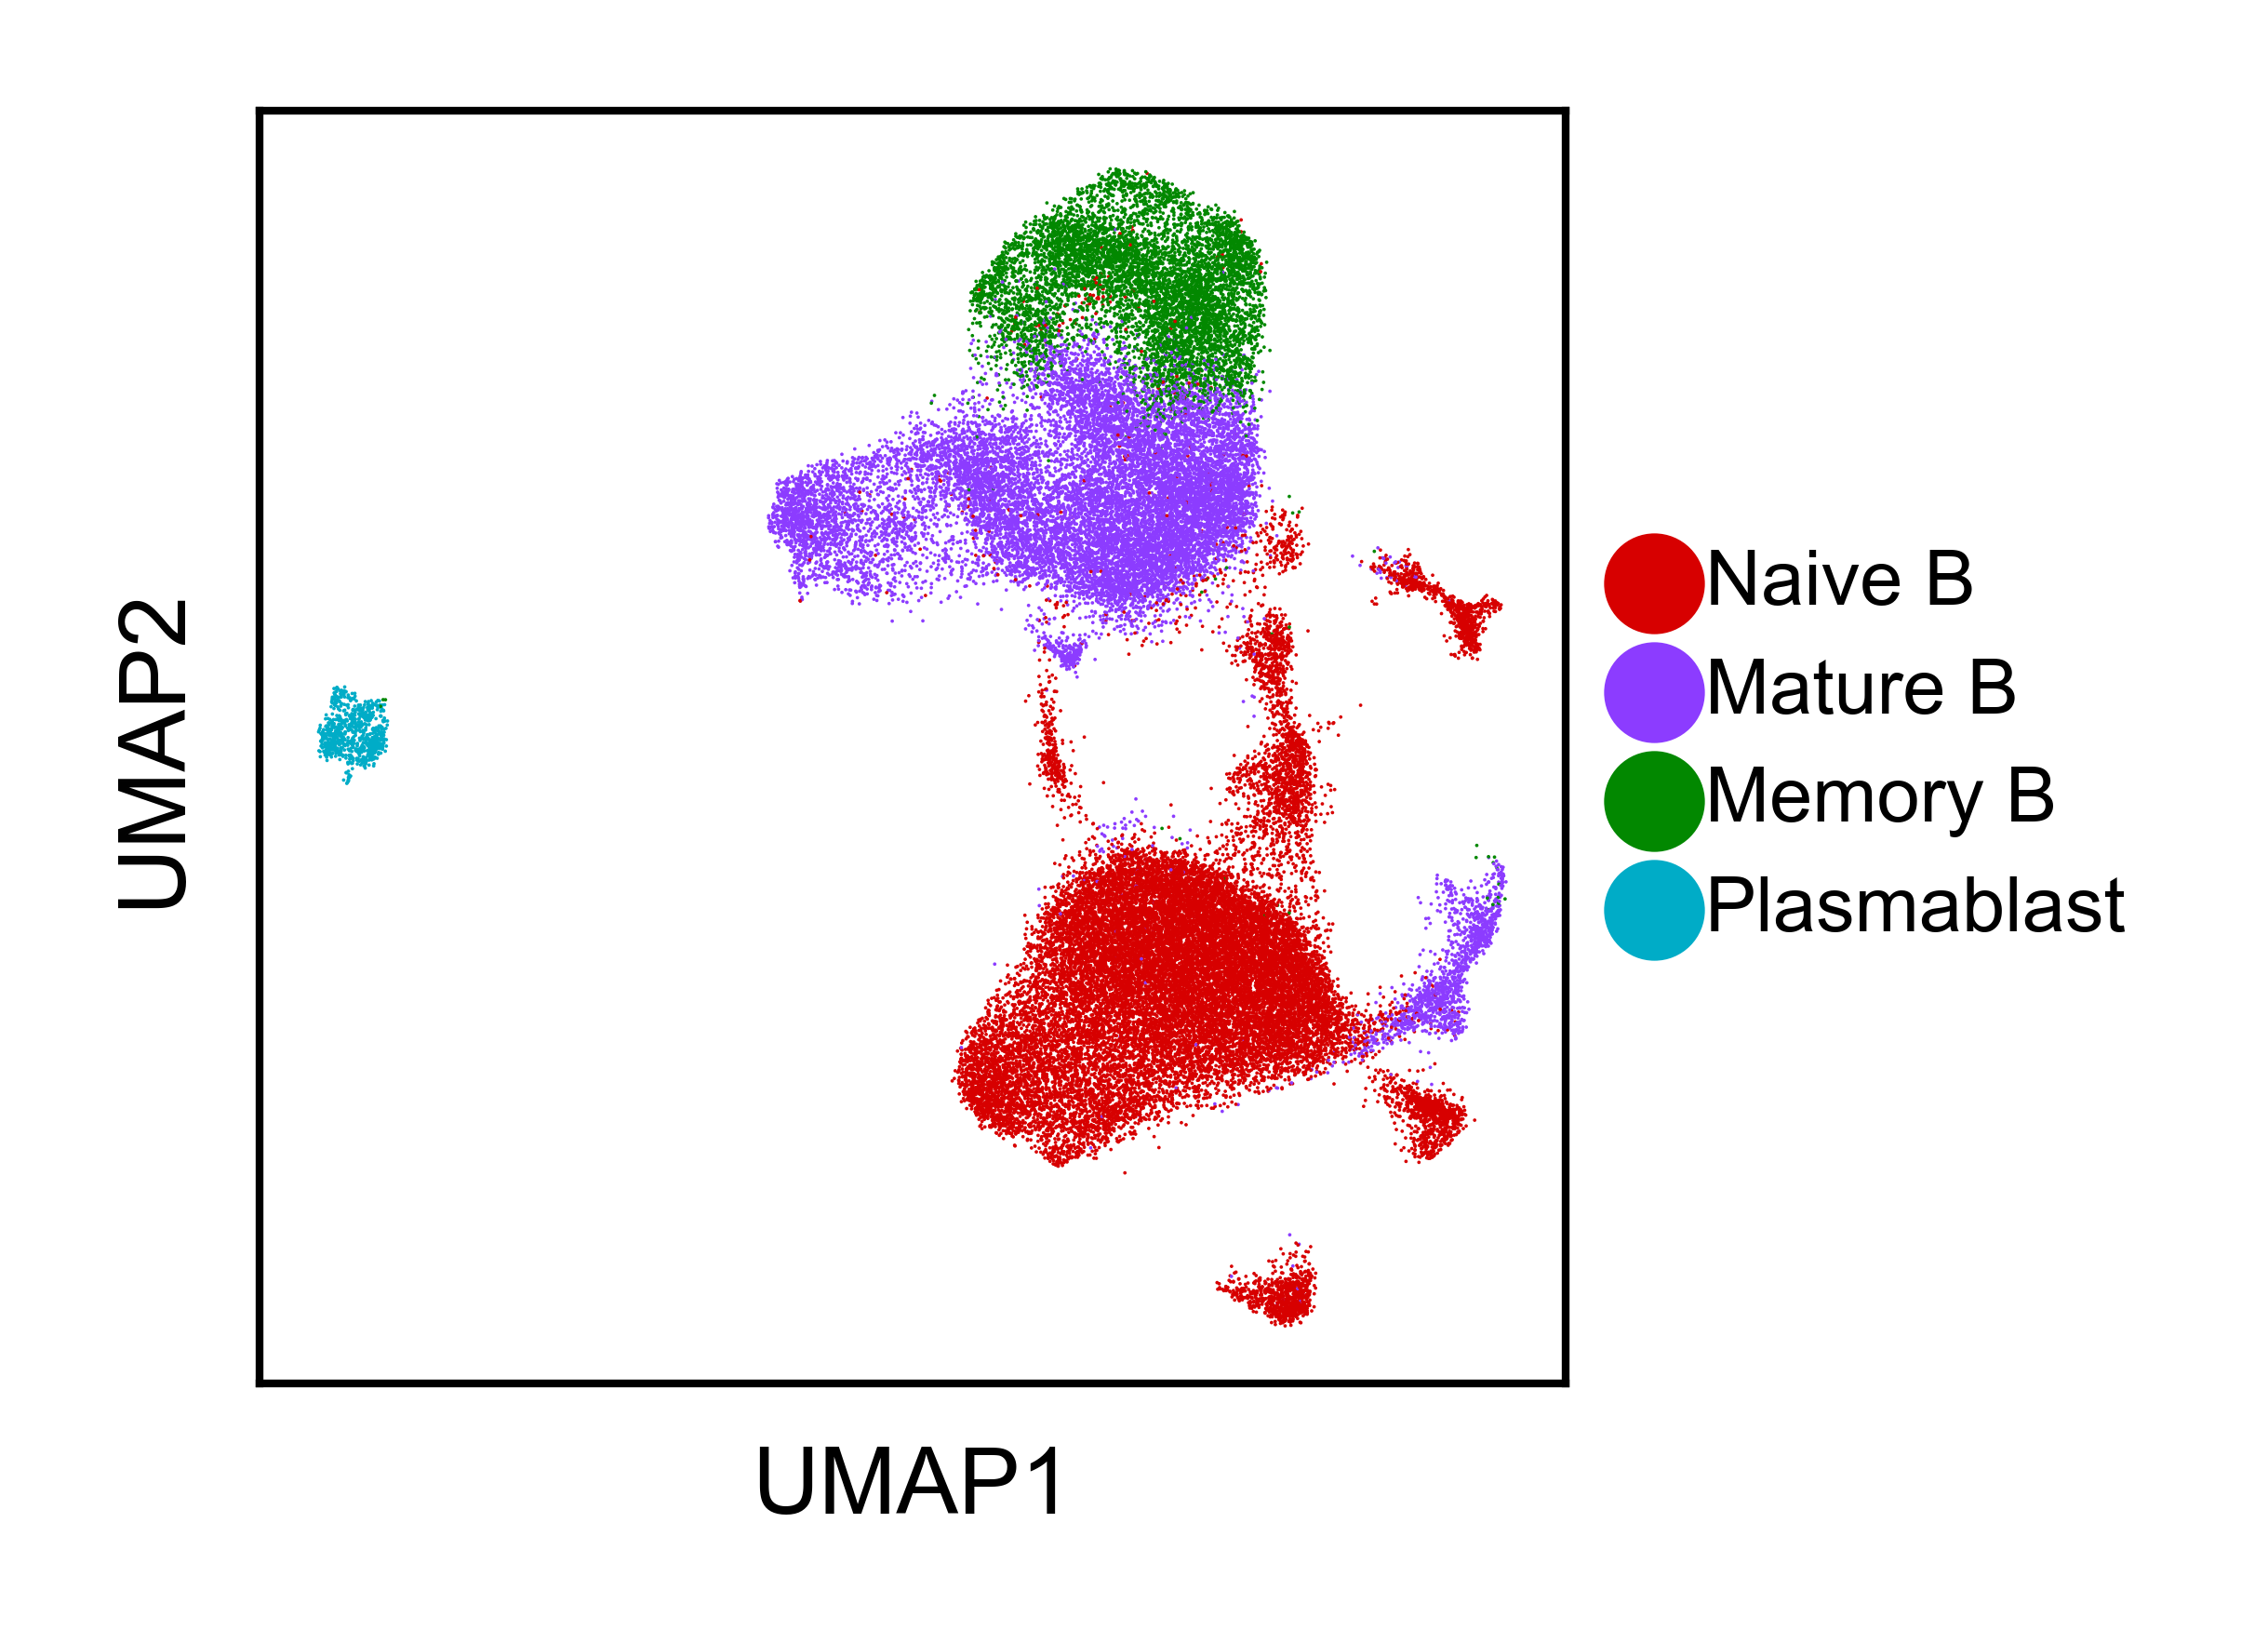

In [17]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'celltype_level3'
# cell_colors = {x: palsamplem['race-stage'] = samplem.apply(lambda row: f"{row['race']}-{row['group']}", axis=1)
# Counter(samplem['race-stage'])
#palette[ct] = (0.8, 0.8, 0.8)

order = cells_group[celltype_major]
pal_ordered = [palette_all[c] for c in order]

d.obs['celltype_level3_new'] = d.obs['celltype_level3'] #[
#     newlabel_dict[x] for x in d.obs['celltype_level3']
# ]

d.obs['celltype_level3_new'] = pd.Categorical(
    d.obs['celltype_level3_new'],
    categories=order,
    ordered=True
)

sc.pl.umap(
    d,
    color='celltype_level3_new',
    palette=pal_ordered,
    size=.2,
    ax=ax,
    legend_fontsize='small',
    # legend_loc='right',
    show=False,
    title=''
)

plt.savefig(f'plots/F7_2/{celltype_major}_celltype.svg')

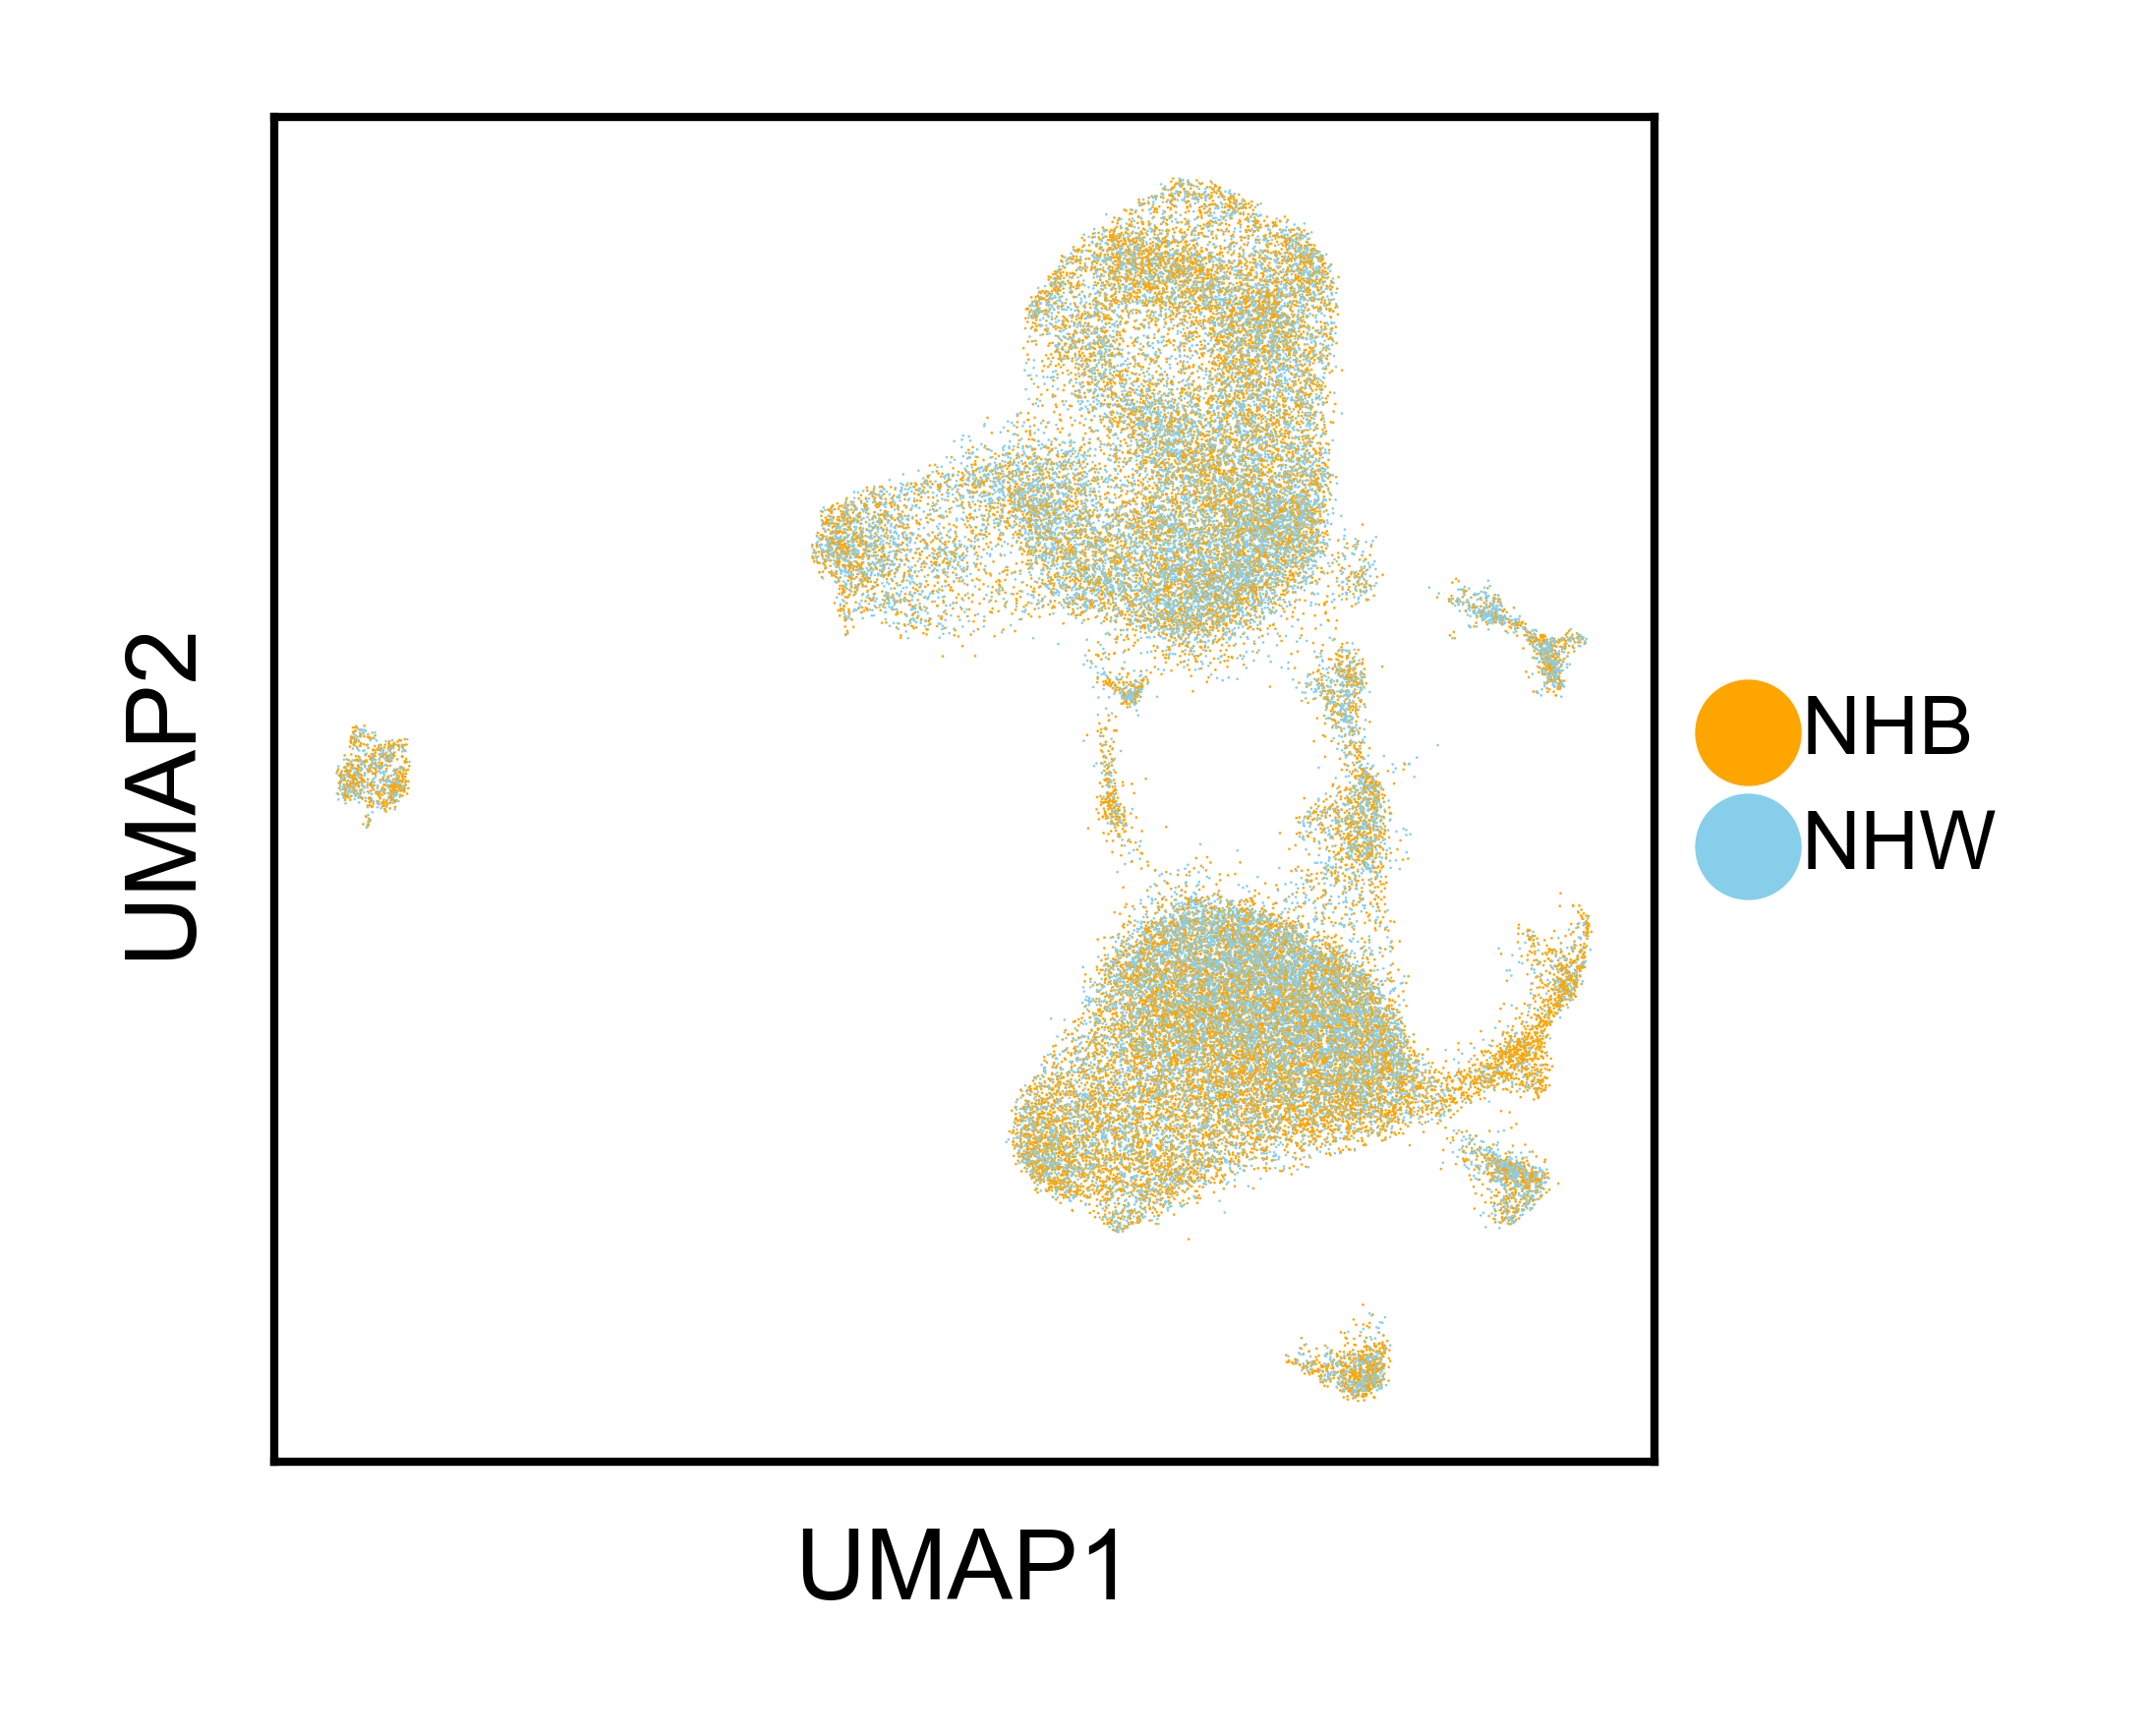

In [16]:
fig, ax = plt.subplots(figsize=(1.5, 1.5))

covar = 'race'
d.obs['race'] = [str(x).replace('1','NHB').replace('0','NHW') for x in d.obs['race']]


order = cells_group[celltype_major]
pal_ordered = [palette_all[c] for c in order]

sc.pl.umap(
    d,
    color=covar,
    palette=['orange','skyblue'],
    size=.1,
    ax=ax,
    legend_fontsize='small',
    # legend_loc='right',
    show=False,
    title=''
)

plt.savefig(f'plots/F7_2/{celltype_major}_race.svg')

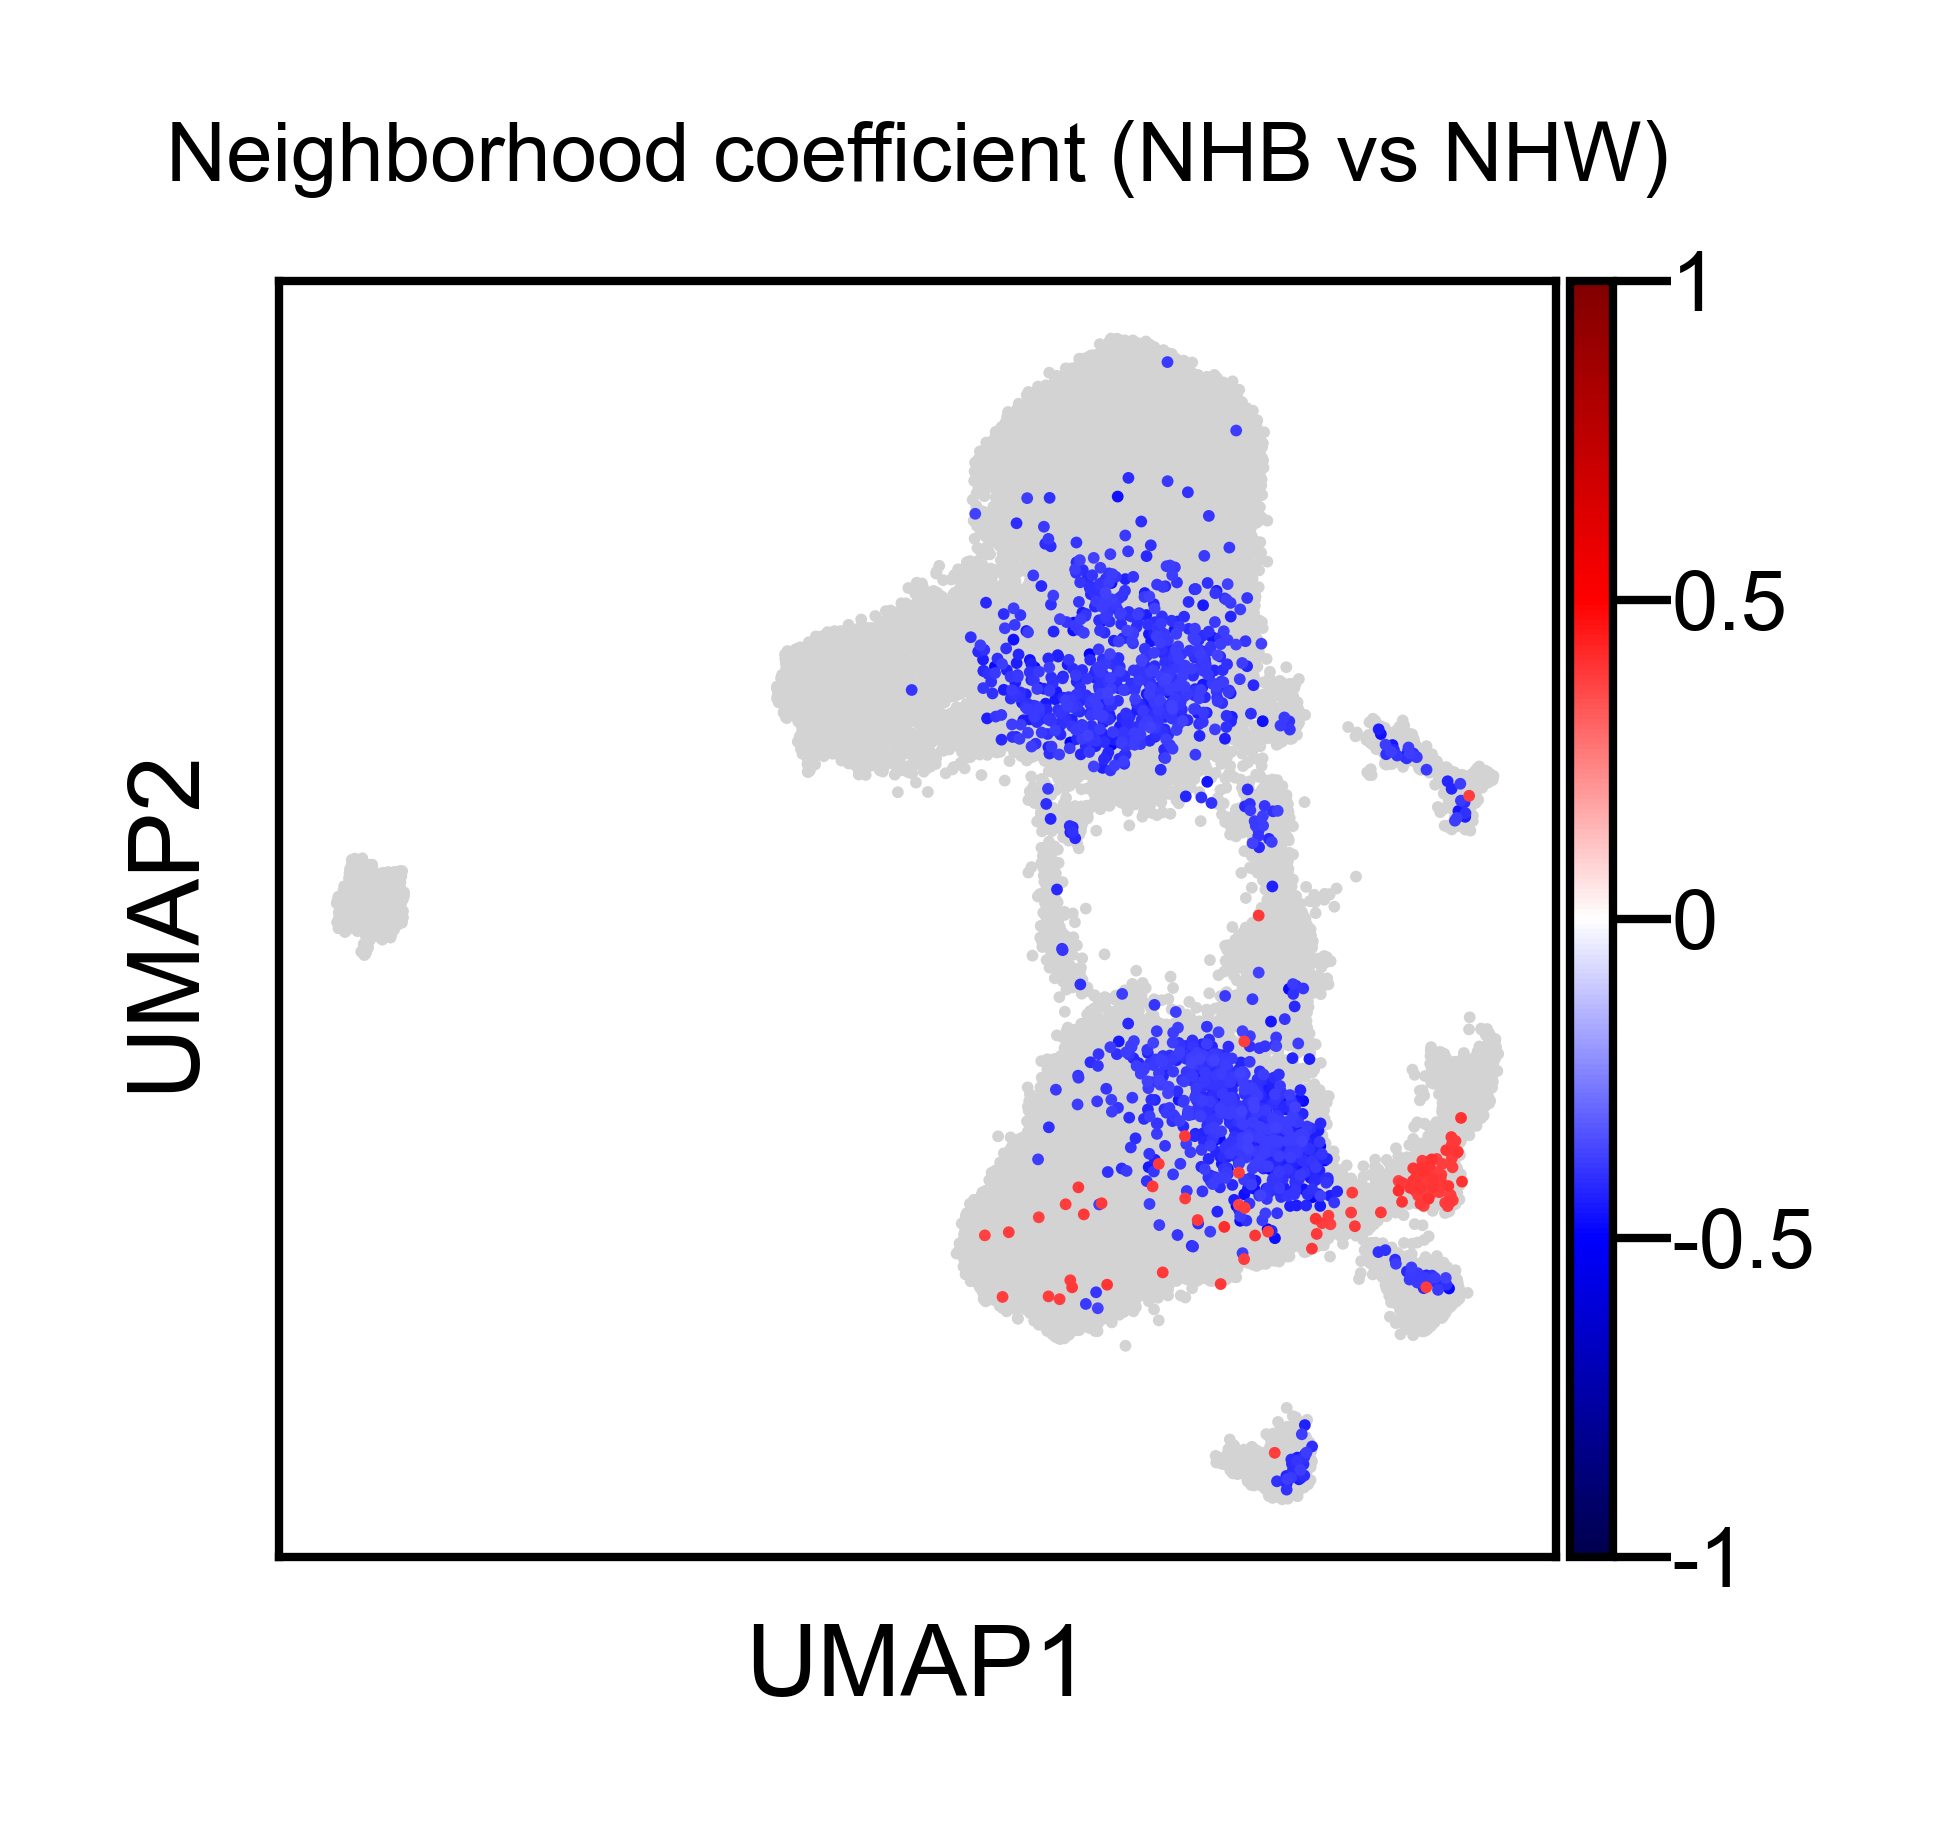

In [19]:
fig, ax = plt.subplots(figsize=(1.5, 1.4))

covar = 'race' 

coef_col = f"{covar}_coef"
fdr_col = f"{covar}_coef_fdr"
color_col = f"{covar}_coef_plot"

d.obs[color_col] = np.where(d.obs[fdr_col] < 0.1, d.obs[coef_col], np.nan)   # nan will show as gray in sc.pl.umap
sc.pl.umap(
    d,
    color=color_col,
    s=2,
    ax=ax,
    vmin=-1,
    vmax=1,
    cmap='seismic',
    na_color='lightgray',   # Gray for nan (non-significant)
    title='',
    show=False         # So you can further edit if needed
)

cbar = ax.collections[0].colorbar
ticks = [-1, -0.5, 0, 0.5, 1]
cbar.set_ticks(ticks)
cbar.set_ticklabels([str(t) for t in ticks])


ax.set_title('Neighborhood coefficient (NHB vs NHW)',fontsize=5)
plt.savefig(f'plots/F7_2/{celltype_major}_NbCoeff.svg')

In [20]:
tmp = d[(d.obs[fdr_col]<0.1) & (d.obs[coef_col]>0)]
cnt = Counter(tmp.obs['celltype_level3'])
total = sum(cnt.values())

for k,v in cnt.items():
    print(f"{k}: {v} ({v/total*100:.2f}%)")

Naive B: 39 (37.86%)
Mature B: 64 (62.14%)


In [21]:
tmp = d[(d.obs[fdr_col]<0.1) & (d.obs[coef_col]<0)]
cnt = Counter(tmp.obs['celltype_level3'])
total = sum(cnt.values())

for k,v in cnt.items():
    print(f"{k}: {v} ({v/total*100:.2f}%)")

Naive B: 844 (55.93%)
Mature B: 647 (42.88%)
Memory B: 18 (1.19%)


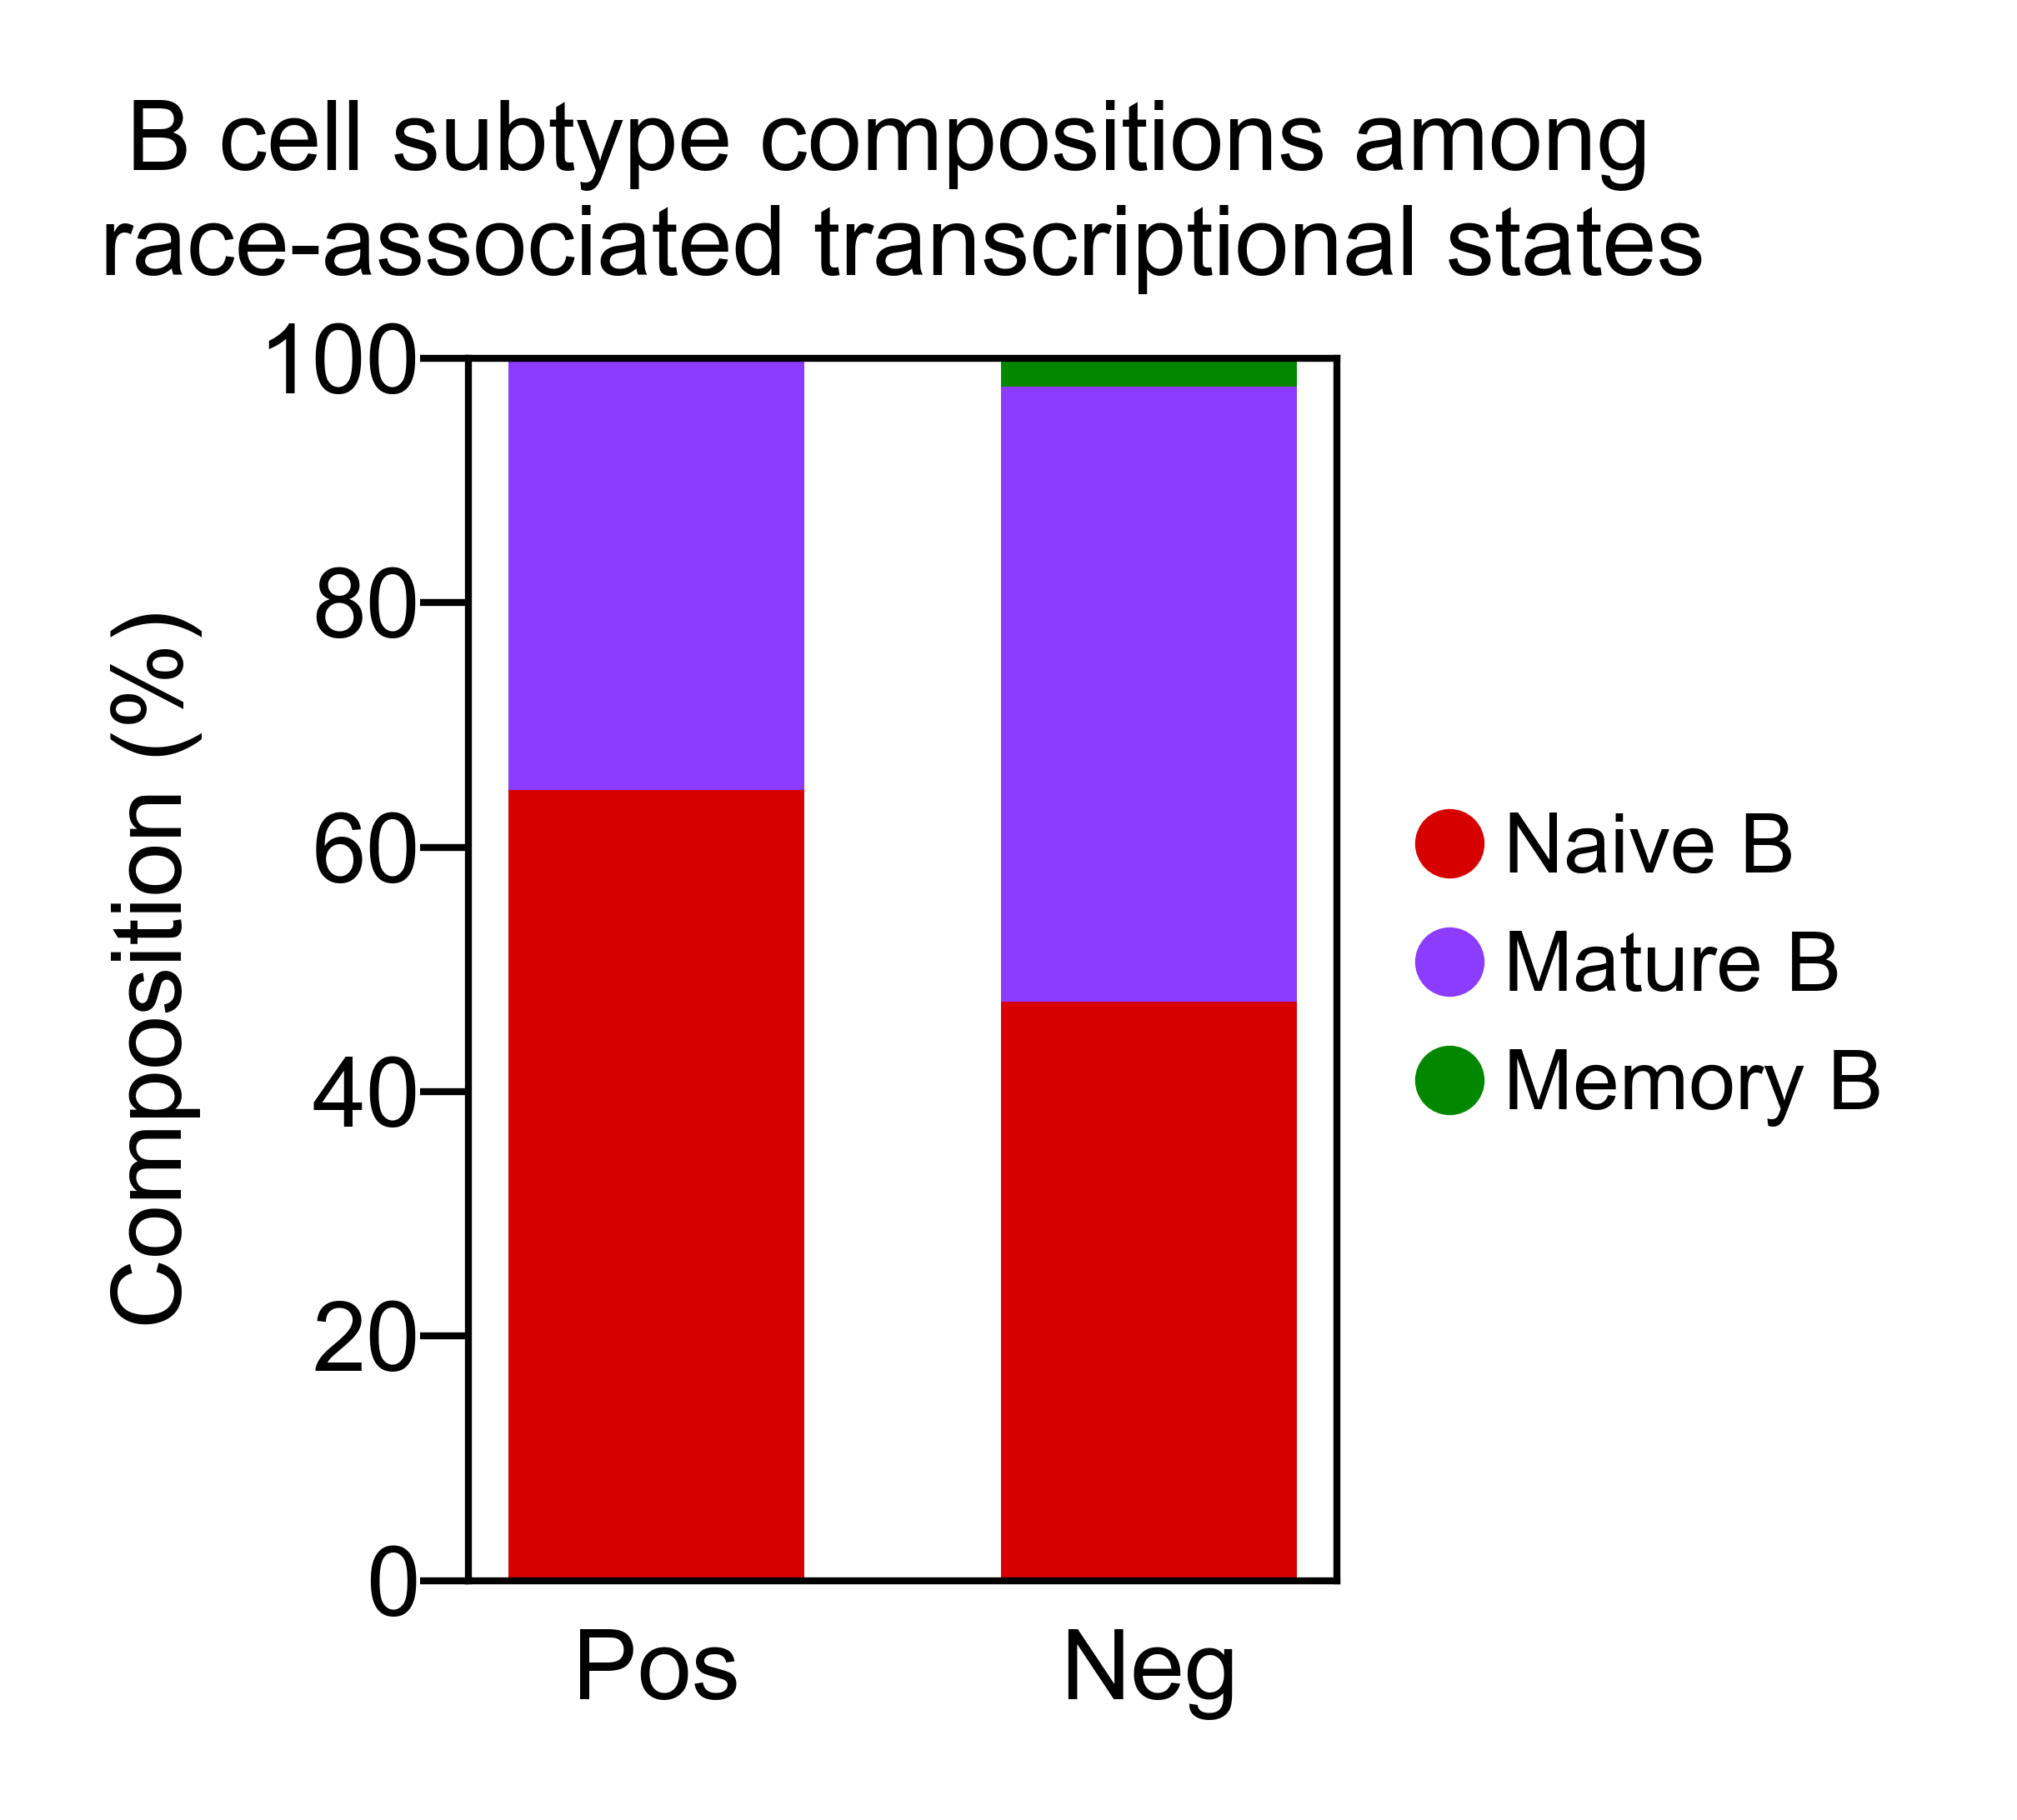

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

covar = "race"
fdr_col = f"{covar}_coef_fdr"
coef_col = f"{covar}_coef"

# positive-associated cells
tmp_pos = d[(d.obs[fdr_col] < 0.1) & (d.obs[coef_col] > 0)]
cnt_pos = Counter(tmp_pos.obs["celltype_level3"])

# negative-associated cells
tmp_neg = d[(d.obs[fdr_col] < 0.1) & (d.obs[coef_col] < 0)]
cnt_neg = Counter(tmp_neg.obs["celltype_level3"])

# all cell types appearing in either group
celltypes = sorted(set(cnt_pos.keys()) | set(cnt_neg.keys()))

# count table
df_counts = pd.DataFrame({
    "cell_type": celltypes,
    "pos_count": [cnt_pos.get(ct, 0) for ct in celltypes],
    "neg_count": [cnt_neg.get(ct, 0) for ct in celltypes],
})

# optional: keep only cell types present in your palette/order
celltype_order = [ct for ct in palette_all.keys() if ct in df_counts["cell_type"].values]
df_counts["cell_type"] = pd.Categorical(df_counts["cell_type"], categories=celltype_order, ordered=True)
df_counts = df_counts.sort_values("cell_type").reset_index(drop=True)

# calculate percentages within pos and neg separately
df_counts["pos_pct"] = df_counts["pos_count"] / df_counts["pos_count"].sum() * 100
df_counts["neg_pct"] = df_counts["neg_count"] / df_counts["neg_count"].sum() * 100

# reshape for plotting
dat = (
    df_counts
    .set_index("cell_type")[["pos_pct", "neg_pct"]]
    .T
)
dat.index = ["Pos", "Neg"]

# colors in desired order
pal_ordered = [palette_all[ct] for ct in dat.columns]

# plot
fig, ax = plt.subplots(figsize=(2,1.8))

bottom = pd.Series(0, index=dat.index)

for ct, color in zip(dat.columns, pal_ordered):
    ax.bar(
        dat.index,
        dat[ct],
        bottom=bottom,
        color=color,
        label=ct,
        width=0.6
    )
    bottom += dat[ct]

ax.set_ylabel("Composition (%)", fontsize=7)
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", labelsize=7)
ax.set_title('B cell subtype compositions among \nrace-associated transcriptional states')


# plot legend
from matplotlib.lines import Line2D

label_map = {
'Naive B': 'Naive B', 
'Mature B': 'Mature B', 
'Memory B': 'Memory B', 
'Plasmablast': 'Plasmablast'
}

handles = [
    Line2D(
        [0], [0],
        marker='o',
        linestyle='None',
        markerfacecolor=palette_all[ct],
        markeredgecolor=palette_all[ct],
        markersize=4,
        label=label_map.get(ct, ct)
    )
    for ct in dat.columns
]

ax.legend(
    handles=handles,
    title="",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=6,
    handletextpad=0.4
)

plt.tight_layout()
plt.savefig("plots/S4/B_asso_composition.pdf", bbox_inches="tight")
plt.show()

## DzState

In [9]:
celltype_major = 'B'

In [10]:
cts = 0


for group in ['HRL','DCIS','BC']:

    for db in ['hallmark','immport']:

        cts += 1
        
        raw = pd.read_csv(
            f'data/Figure7_2/CNArankNHBvsW_{celltype_major}_{group}_{db}.csv', 
            index_col=0)
        
        dfp = raw#[raw['FDR q-val']<0.05].sort_values('NES', ascending=False)

        dfp['Tag %'] = (
            dfp['Tag %']
            .astype(str)
            .apply(lambda x: eval(x) if '/' in x else float(x))
        )
        dfp['Tag %'] = dfp['Tag %'] * 100
        dfp['log_p'] = -np.log10(dfp['FDR q-val'].replace(0, 1e-300))
        
        # Sort by NES
        dfp = dfp.sort_values('NES', ascending=False)
        
        # filter - 
        # dfp = dfp[dfp['Tag %']>=30]
        dfp['Term'] = [x.removeprefix('HALLMARK_').replace('_',' ').upper() for x in dfp['Term']]


        dfp['analysis_group'] = [group]*dfp.shape[0]
        dfp['analysis_db'] = [db]*dfp.shape[0]

        out = dfp if cts==1 else pd.concat([out, dfp])


out        

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,log_p,analysis_group,analysis_db
0,prerank,MITOTIC SPINDLE,0.714117,1.835074,0.0,0.000000,0.000,59.798995,17.41%,TRIO;SSH2;RAPGEF5;SPTBN1;DOCK2;EZR;NEDD9;NIN;G...,300.000000,HRL,hallmark
2,prerank,UV RESPONSE DN,0.682391,1.742246,0.0,0.000000,0.000,33.093525,8.95%,ANXA4;ATP2B1;PRKCE;PTEN;SMAD3;CELF2;ANXA2;SIPA...,300.000000,HRL,hallmark
3,prerank,G2M CHECKPOINT,0.616318,1.600018,0.0,0.001646,0.005,49.230769,21.11%,LBR;FOXN3;SMAD3;SLC38A1;STAG1;RPS6KA5;PAFAH1B1...,2.783654,HRL,hallmark
4,prerank,PI3K AKT MTOR SIGNALING,0.626468,1.562955,0.0,0.003456,0.014,53.921569,22.02%,PRKCB;PTEN;VAV3;MAPK1;ACTR2;PIKFYVE;ACTR3;CDKN...,2.461434,HRL,hallmark
5,prerank,PROTEIN SECRETION,0.612534,1.518879,0.0,0.005529,0.026,60.000000,20.48%,SSPN;AP3B1;ADAM10;MAPK1;ARFGEF1;MON2;DOP1A;SGM...,2.257314,HRL,hallmark
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4,prerank,INTERLEUKIN-1 FAMILY SIGNALING,-0.575349,-1.776524,0.0,0.004313,0.023,44.520548,11.77%,RPS27A;PTPN6;PSMB9;PSMA7;PSME1;ALOX5;UBB;UBA52...,2.365175,BC,immport
3,prerank,INNATE IMMUNE RESPONSE IN MUCOSA,-0.885114,-1.785876,0.0,0.004529,0.019,16.666667,0.27%,RPL39;FAU,2.343986,BC,immport
2,prerank,NEUTROPHIL DEGRANULATION,-0.534711,-1.788598,0.0,0.005464,0.017,35.176991,11.33%,EEF1A1;FTL;HLA-B;EEF2;B2M;PTPN6;CTSH;GMFG;HLA-...,2.262513,BC,immport
1,prerank,ANTIGEN PROCESSING AND PRESENTATION,-0.639577,-1.863355,0.0,0.000863,0.002,29.347826,6.51%,HLA-DPA1;HLA-B;CD74;B2M;CD1C;HLA-DRA;CTSH;HLA-...,3.064145,BC,immport


### HRL

In [11]:
DzState, db = 'HRL', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['B CELL DIFFERENTIATION', 'B CELL ACTIVATION',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',
       'INTERLEUKIN-2 FAMILY SIGNALING',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'RESPIRATORY BURST INVOLVED IN DEFENSE RESPONSE',
       'GAMMA-DELTA T CELL ACTIVATION', 'RAP1 SIGNALLING',
       'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
       'GROWTH HORMONE RECEPTOR SIGNALING',
       'NATURAL KILLER CELL ACTIVATION', 'TOLERANCE INDUCTION',
       'LYMPHOCYTE PROLIFERATION', 'LEUKOCYTE HOMEOSTASIS',
       'T CELL COSTIMULATION', 'LYMPHOCYTE COSTIMULATION',
       'ALPHA-BETA T CELL ACTIVATION',
       'NATURAL KILLER CELL MEDIATED CYTOTO

In [12]:
paths_relevant = [
    'B CELL DIFFERENTIATION', 
    'B CELL ACTIVATION',
       'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS',
       # 'STIMULATORY C-TYPE LECTIN RECEPTOR SIGNALING PATHWAY',
       'INTERLEUKIN-2 FAMILY SIGNALING',
       'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY',
       'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS',
       # 'RESPIRATORY BURST INVOLVED IN DEFENSE RESPONSE',
       # 'GAMMA-DELTA T CELL ACTIVATION', 
      'RAP1 SIGNALLING',
       # 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
       # 'GROWTH HORMONE RECEPTOR SIGNALING',
       # 'NATURAL KILLER CELL ACTIVATION', 
    # 'TOLERANCE INDUCTION',
       'LYMPHOCYTE PROLIFERATION', 
    'LEUKOCYTE HOMEOSTASIS',
       # 'T CELL COSTIMULATION', 
    'LYMPHOCYTE COSTIMULATION',
       # 'ALPHA-BETA T CELL ACTIVATION',
       # 'NATURAL KILLER CELL MEDIATED CYTOTOXICITY',
       # 'T CELL PROLIFERATION', 
    # 'NATURAL KILLER CELL DIFFERENTIATION',
       # 'LEUKOCYTE DEGRANULATION', 
    # 'T CELL DIFFERENTIATION',
       # 'NATURAL KILLER CELL MEDIATED IMMUNITY', 
    'DAP12 INTERACTIONS',
       'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       'CLASS I MHC MEDIATED ANTIGEN PROCESSING & PRESENTATION',
       # 'MYELOID LEUKOCYTE ACTIVATION',
       'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE',
       # 'COSTIMULATION BY THE CD28 FAMILY', 
      'GERMINAL CENTER FORMATION',
       'NEGATIVE REGULATION OF ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY',
       'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS',
       # 'ANTIFUNGAL INNATE IMMUNE RESPONSE',
       'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'INTERLEUKIN-20 FAMILY SIGNALING',
       'FC EPSILON RECEPTOR (FCERI) SIGNALING',
       # 'ACTIVATION OF INNATE IMMUNE RESPONSE', 
       'INTERLEUKIN-7 SIGNALING',
       'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY',
       # 'NEGATIVE REGULATION OF CYTOPLASMIC PATTERN RECOGNITION RECEPTOR SIGNALING PATHWAY',
       'DIAPEDESIS',
       'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY',
       'NEGATIVE REGULATION OF IMMUNE RESPONSE',
       'COMPLEMENT RECEPTOR MEDIATED SIGNALING PATHWAY',
       'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION',
       'INTERFERON GAMMA SIGNALING', 
       'MONONUCLEAR CELL MIGRATION',
       # 'C-TYPE LECTIN RECEPTORS (CLRS)', 
       'INTERLEUKIN-6 FAMILY SIGNALING',
       # 'ADVANCED GLYCOSYLATION ENDPRODUCT RECEPTOR SIGNALING',
       # 'ALPHA-PROTEIN KINASE 1 SIGNALING PATHWAY',
       # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
       'ANTIMICROBIAL HUMORAL RESPONSE',
       'INNATE IMMUNE RESPONSE IN MUCOSA'
]

In [13]:
dfp_sel = dfp[dfp['Term'].isin(paths_relevant)]
dfp_sel.to_csv(f'data/Tables/B_{DzState}.csv')

In [14]:
short_name_map = {
    'B CELL DIFFERENTIATION': 'B CELL DIFF',
    'B CELL ACTIVATION': 'B CELL ACTIV',
    'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS': 'FCγR PHAGOCYTOSIS',
    'INTERLEUKIN-2 FAMILY SIGNALING': 'IL-2 FAMILY SIG',
    'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY': 'ANTIGEN RECEPTOR SIG',
    'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY': 'FCR STIMULATORY SIG',
    'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS': 'FCγR PHAGOCYTOSIS SIG',
    'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS': 'PHAGOCYTIC SURF R SIG',
    'RAP1 SIGNALLING': 'RAP1 SIG',
    'LYMPHOCYTE PROLIFERATION': 'LYMPHOCYTE PROLIF',
    'LEUKOCYTE HOMEOSTASIS': 'LEUKOCYTE HOMEOSTASIS',
    'LYMPHOCYTE COSTIMULATION': 'LYMPHOCYTE COSTIMULATION',
    'DAP12 INTERACTIONS': 'DAP12 INTERACTIONS',
    'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE': 'LEUKOCYTE ACTIV',
    'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE': 'IMMUNE CELL ACTIVATION',
    'CLASS I MHC MEDIATED ANTIGEN PROCESSING & PRESENTATION': 'MHC I AG PRESENT',
    'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE': 'LYMPHOCYTE ACTIV',
    'GERMINAL CENTER FORMATION': 'GERMINAL CENTER FORMATION',
    'NEGATIVE REGULATION OF ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY': 'NEG AG RECEPTOR SIG',
    'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS': 'IMMUNE R DIVERSIFICATION',
    'SIGNALING BY THE B CELL RECEPTOR (BCR)': 'BCR SIG',
    'INTERLEUKIN-20 FAMILY SIGNALING': 'IL-20 FAMILY SIG',
    'FC EPSILON RECEPTOR (FCERI) SIGNALING': 'FCεRI SIG',
    'INTERLEUKIN-7 SIGNALING': 'IL-7 SIG',
    'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY': 'INNATE IMMUNE ACTIV',
    'DIAPEDESIS': 'DIAPEDESIS',
    'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY': 'INNATE SURFACE RECEPTOR SIG',
    'NEGATIVE REGULATION OF IMMUNE RESPONSE': 'NEG IMMUNE REG',
    'COMPLEMENT RECEPTOR MEDIATED SIGNALING PATHWAY': 'COMPLEMENT RECEPTOR SIG',
    'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION': 'NEG LEUKOCYTE ACTIV',
    'INTERFERON GAMMA SIGNALING': 'IFNγ SIG',
    'MONONUCLEAR CELL MIGRATION': 'MONONUCLEAR CELL MIGRATION',
    'INTERLEUKIN-6 FAMILY SIGNALING': 'IL-6 FAMILY SIG',
    'ANTIMICROBIAL HUMORAL RESPONSE': 'ANTIMICROBIAL HUMORAL RESP',
    'INNATE IMMUNE RESPONSE IN MUCOSA': 'MUCOSAL INNATE IMMUNITY',
}

In [15]:
triangle_map = {
    'B CELL DIFFERENTIATION':
        {"marker": "^", "color": "#FDBF11"},  # yellow; B-cell differentiation / GC-like

    'B CELL ACTIVATION':
        {"marker": "^", "color": "#F47C20"},  # orange; B-cell / lymphocyte activation

    'FCGAMMA RECEPTOR (FCGR) DEPENDENT PHAGOCYTOSIS':
        {"marker": "^", "color": "#6B4423"},  # brown; Fc receptor / phagocytosis

    'INTERLEUKIN-2 FAMILY SIGNALING':
        {"marker": "^", "color": "#F47C20"},  # orange; cytokine / lymphocyte signaling

    'ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY':
        {"marker": "^", "color": "#F47C20"},  # orange; antigen receptor signaling

    'FC RECEPTOR MEDIATED STIMULATORY SIGNALING PATHWAY':
        {"marker": "^", "color": "#6B4423"},  # brown; Fc receptor signaling

    'FC-GAMMA RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS':
        {"marker": "^", "color": "#6B4423"},  # brown; FcγR / phagocytosis

    'IMMUNE RESPONSE-REGULATING CELL SURFACE RECEPTOR SIGNALING PATHWAY INVOLVED IN PHAGOCYTOSIS':
        {"marker": "^", "color": "#6B4423"},  # brown; phagocytic surface receptor signaling

    'RAP1 SIGNALLING':
        {"marker": "^", "color": "#009E57"},  # green; migration / adhesion signaling

    'LYMPHOCYTE PROLIFERATION':
        {"marker": "^", "color": "#FDBF11"},  # yellow; lymphocyte proliferation

    'LEUKOCYTE HOMEOSTASIS':
        {"marker": "^", "color": "#FDBF11"},  # yellow; immune homeostasis

    'LYMPHOCYTE COSTIMULATION':
        {"marker": "^", "color": "#F47C20"},  # orange; lymphocyte activation / costimulation

    'DAP12 INTERACTIONS':
        {"marker": "^", "color": "#28A9E0"},  # blue; innate immune receptor adaptor

    'LEUKOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#F47C20"},  # orange; leukocyte activation

    'CELL ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#F47C20"},  # orange; immune cell activation

    'CLASS I MHC MEDIATED ANTIGEN PROCESSING & PRESENTATION':
        {"marker": "^", "color": "#6B4423"},  # brown; antigen processing / presentation

    'LYMPHOCYTE ACTIVATION INVOLVED IN IMMUNE RESPONSE':
        {"marker": "^", "color": "#F47C20"},  # orange; lymphocyte activation

    'GERMINAL CENTER FORMATION':
        {"marker": "^", "color": "#FDBF11"},  # yellow; B-cell / germinal center biology

    'NEGATIVE REGULATION OF ANTIGEN RECEPTOR-MEDIATED SIGNALING PATHWAY':
        {"marker": "^", "color": "#28A9E0"},  # blue; negative immune regulation

    'SOMATIC DIVERSIFICATION OF IMMUNE RECEPTORS':
        {"marker": "^", "color": "#FDBF11"},  # yellow; B-cell receptor diversification

    'SIGNALING BY THE B CELL RECEPTOR (BCR)':
        {"marker": "^", "color": "#F47C20"},  # orange; BCR / antigen receptor signaling

    'INTERLEUKIN-20 FAMILY SIGNALING':
        {"marker": "^", "color": "#F47C20"},  # orange; cytokine signaling

    'FC EPSILON RECEPTOR (FCERI) SIGNALING':
        {"marker": "^", "color": "#F47C20"},  # orange; FcεRI signaling

    'INTERLEUKIN-7 SIGNALING':
        {"marker": "^", "color": "#F47C20"},  # orange; cytokine / lymphocyte signaling

    'INNATE IMMUNE RESPONSE-ACTIVATING SIGNALING PATHWAY':
        {"marker": "^", "color": "#6B4423"},  # brown; innate receptor activation

    'DIAPEDESIS':
        {"marker": "^", "color": "#009E57"},  # green; migration / extravasation

    'INNATE IMMUNE RESPONSE ACTIVATING CELL SURFACE RECEPTOR SIGNALING PATHWAY':
        {"marker": "^", "color": "#6B4423"},  # brown; innate surface receptor signaling

    'NEGATIVE REGULATION OF IMMUNE RESPONSE':
        {"marker": "^", "color": "#28A9E0"},  # blue; negative immune regulation

    'COMPLEMENT RECEPTOR MEDIATED SIGNALING PATHWAY':
        {"marker": "^", "color": "#6B4423"},  # brown; complement receptor signaling

    'NEGATIVE REGULATION OF LEUKOCYTE ACTIVATION':
        {"marker": "^", "color": "#28A9E0"},  # blue; negative leukocyte regulation

    'INTERFERON GAMMA SIGNALING':
        {"marker": "^", "color": "#F47C20"},  # orange; inflammatory cytokine signaling

    'MONONUCLEAR CELL MIGRATION':
        {"marker": "^", "color": "#009E57"},  # green; migration / trafficking

    'INTERLEUKIN-6 FAMILY SIGNALING':
        {"marker": "^", "color": "#F47C20"},  # orange; cytokine signaling

    'ANTIMICROBIAL HUMORAL RESPONSE':
        {"marker": "v", "color": "#6B4423"},  # brown; humoral / innate effector response

    'INNATE IMMUNE RESPONSE IN MUCOSA':
        {"marker": "v", "color": "#6B4423"},  # brown; mucosal innate immunity
}

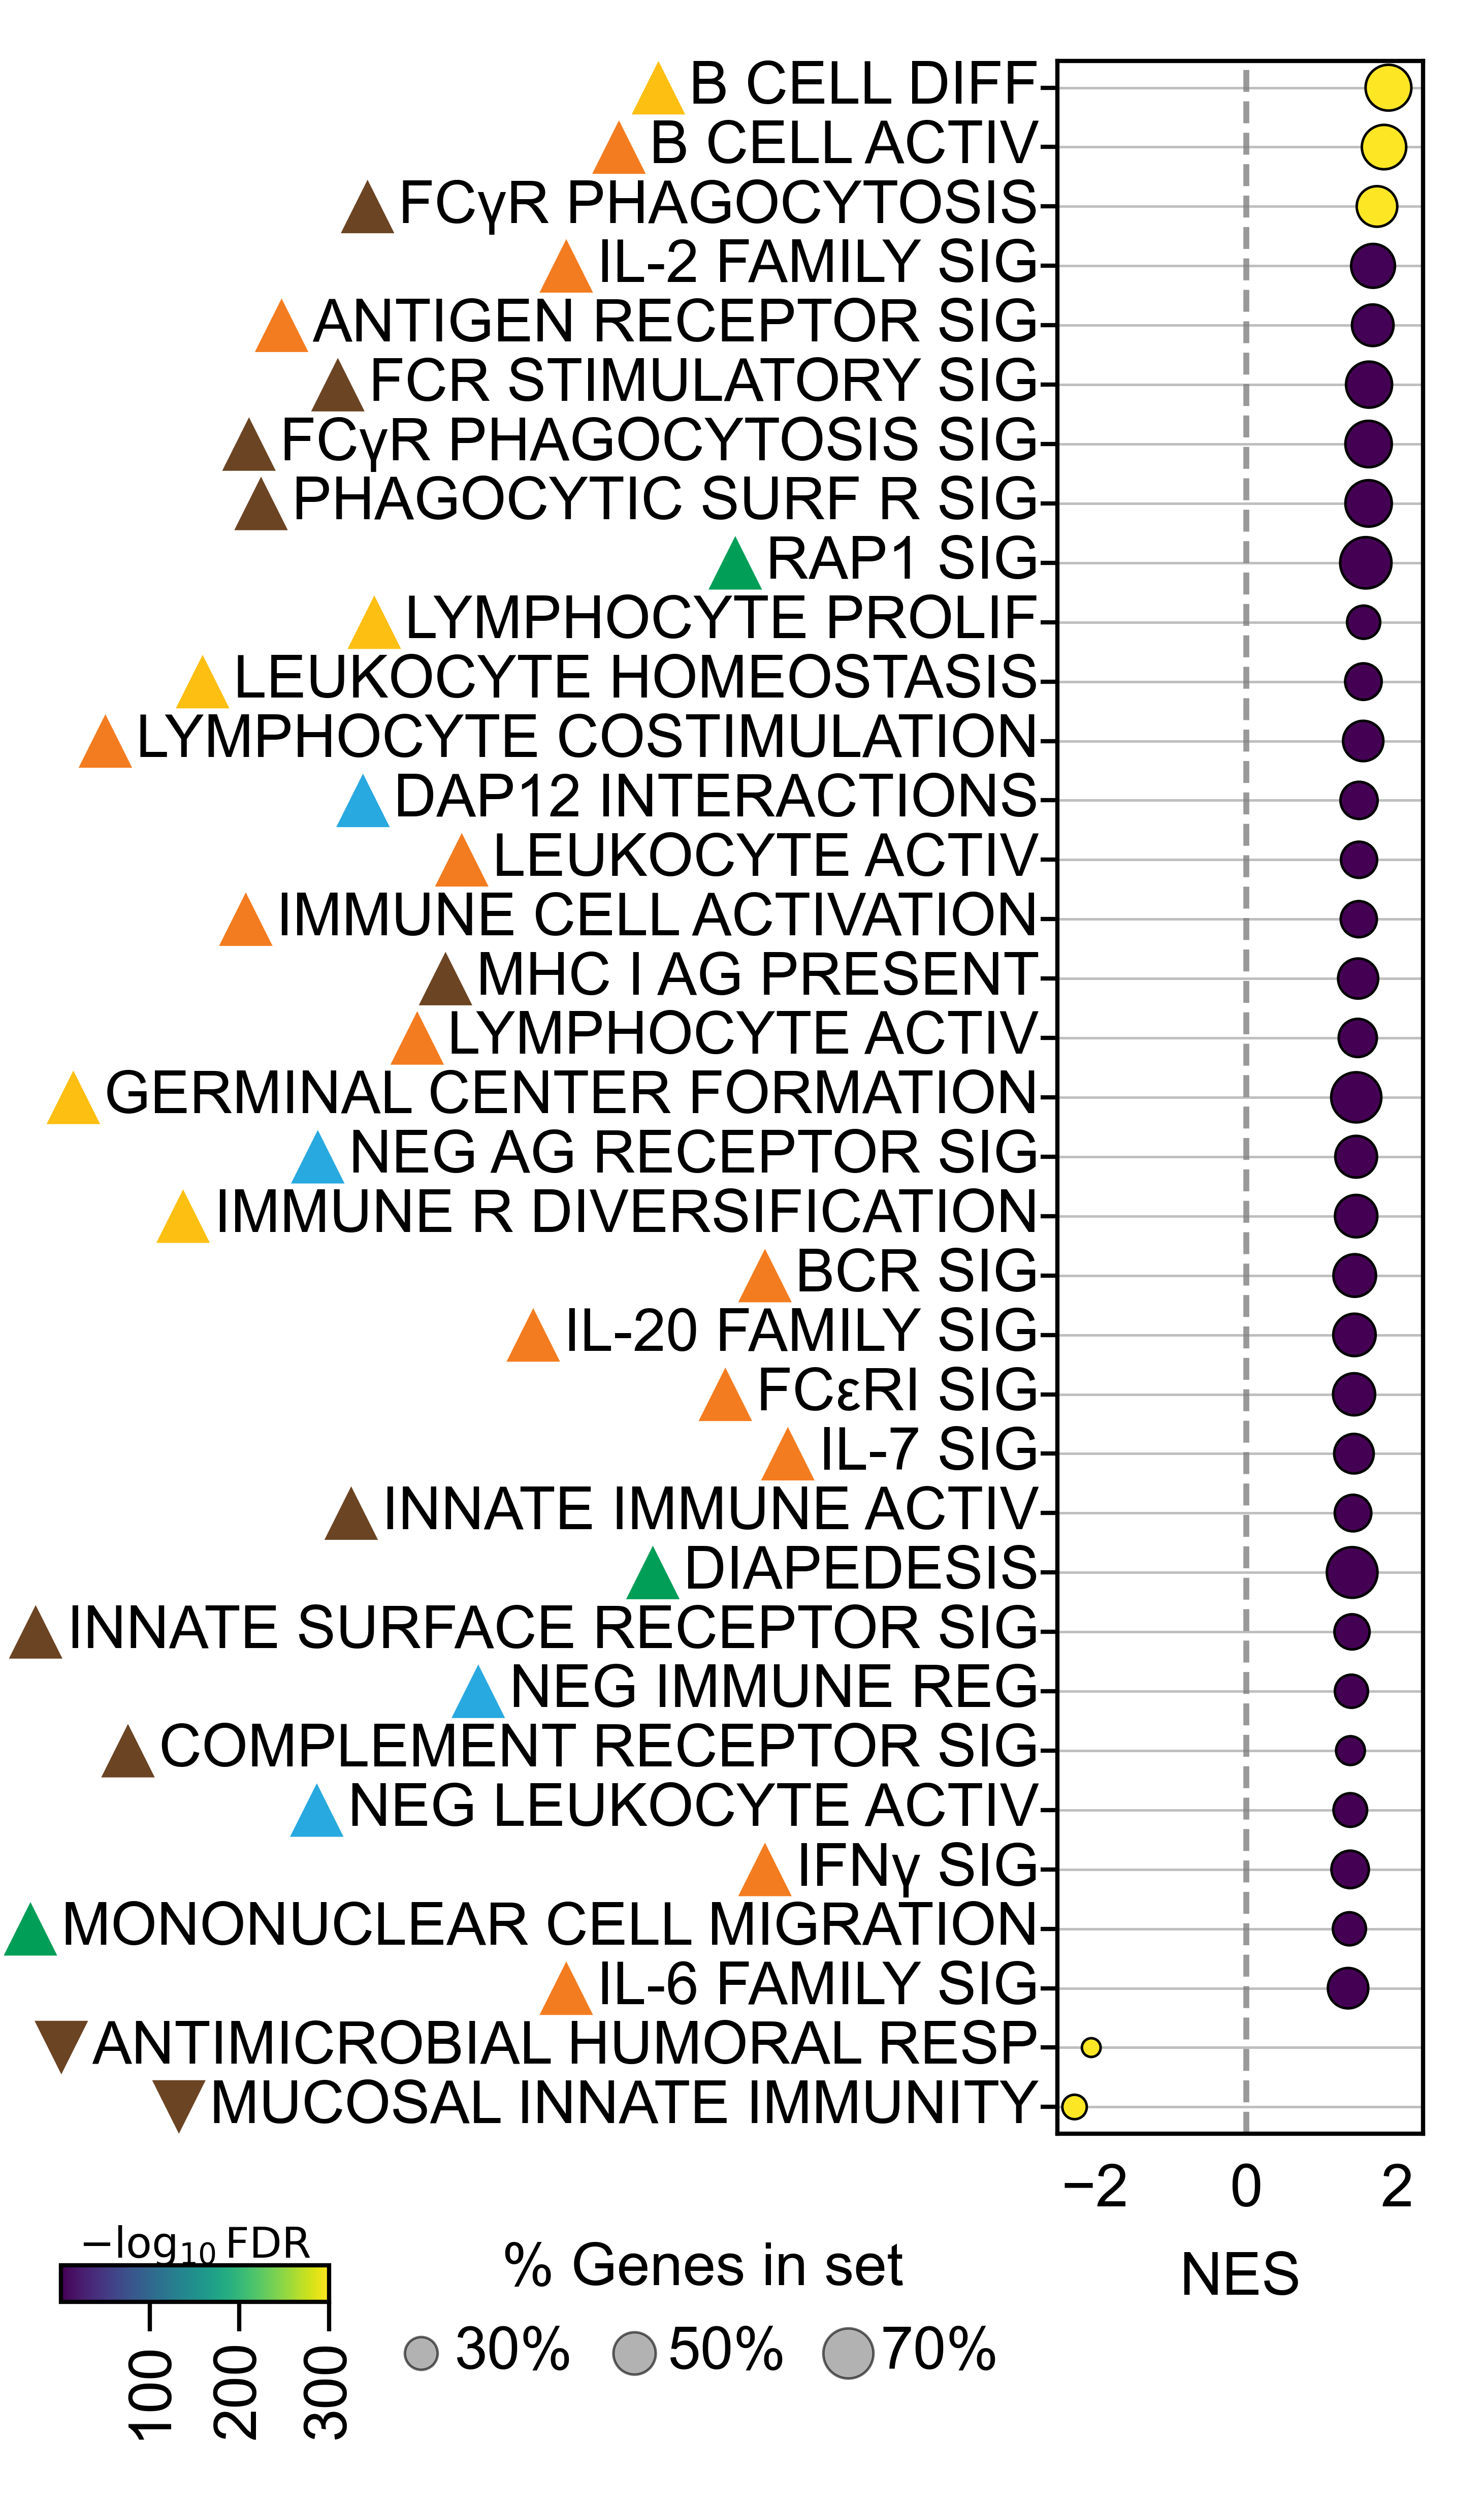

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill
from matplotlib import font_manager as fm

title_map = {"HRL": "High-Risk Lesion", "DCIS": "DCIS", "BC": "Breast Cancer"}

# -----------------------------
# Prepare data
# -----------------------------
dfp2 = dfp[dfp["Term"].isin(paths_relevant)].copy()
dfp2["Term"] = pd.Categorical(dfp2["Term"], categories=paths_relevant, ordered=True)
dfp2 = dfp2.sort_values("Term").reset_index(drop=True)

dfp2["Term_full"] = dfp2["Term"].astype(str)
dfp2["Term_short"] = dfp2["Term_full"].map(short_name_map).fillna(dfp2["Term_full"])
dfp2["Term_plot"] = dfp2["Term_short"].apply(lambda x: fill(str(x), width=38))

# -----------------------------
# Parameters
# -----------------------------
dot_scale = 0.5
cmap = plt.cm.viridis
arial_font = fm.FontProperties(family="Arial")

label_fontsize = 7
label_right_x = -0.05

triangle_gap_px = 20
triangle_size = 40
triangle_half_width_px = 10

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(2, 5))

# Main control:
# larger left = wider ylabel region + narrower bubble box
fig.subplots_adjust(left=0.68, right=0.98, bottom=0.24, top=0.92)

ypos = list(range(len(dfp2)))

sc = ax.scatter(
    dfp2["NES"],
    ypos,
    s=dfp2["Tag %"] * dot_scale,
    c=dfp2["log_p"],
    cmap=cmap,
    edgecolor="black",
    linewidth=0.3,
    zorder=3
)

# -----------------------------
# Manual y labels
# -----------------------------
ax.set_yticks(ypos)
ax.set_yticklabels([])
ax.invert_yaxis()
# shrink top/bottom padding inside bubble box
y_pad = 0.45
ax.set_ylim(len(dfp2) - 1 + y_pad, -y_pad)


label_text_objects = []

for i, row in dfp2.iterrows():
    txt = ax.text(
        label_right_x,
        i,
        row["Term_plot"],
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=label_fontsize,
        clip_on=False
    )
    label_text_objects.append((txt, row["Term_full"], i))

# -----------------------------
# Axes formatting
# -----------------------------
nes_max = dfp2["NES"].abs().max()
nes_min = dfp2["NES"].min()
ax.set_xlim([nes_min * 1.1, nes_max * 1.03])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", length=2, labelsize=6, pad=1)
ax.set_title('')#(title_map.get(DzState, DzState), fontsize=10, pad=8)

ax.grid(axis="y", linestyle="-", linewidth=0.3, color="gray", alpha=0.5, zorder=0)
ax.axvline(x=0, linestyle="--", linewidth=0.7, color="gray", alpha=0.8, zorder=1)

# -----------------------------
# Draw once, then measure manual labels
# -----------------------------
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

label_bboxes = [
    txt.get_window_extent(renderer=renderer)
    for txt, term_full, i in label_text_objects
]

leftmost_label_x_display = min(b.x0 for b in label_bboxes)
lowest_label_y_display = min(b.y0 for b in label_bboxes)

leftmost_label_x_fig, lowest_label_y_fig = fig.transFigure.inverted().transform(
    (leftmost_label_x_display, lowest_label_y_display)
)

# -----------------------------
# Triangles immediately left of labels
# -----------------------------
for txt, term_full, i in label_text_objects:
    tri = triangle_map.get(term_full)
    if tri is None:
        continue

    bbox = txt.get_window_extent(renderer=renderer)
    triangle_x_display = bbox.x0 - triangle_gap_px - triangle_half_width_px
    triangle_x_axes = ax.transAxes.inverted().transform((triangle_x_display, bbox.y0))[0]

    ax.scatter(
        triangle_x_axes,
        i,
        marker=tri["marker"],
        s=triangle_size,
        color=tri["color"],
        edgecolor="none",
        transform=ax.get_yaxis_transform(),
        clip_on=False,
        zorder=5
    )

# -----------------------------
# Colorbar: left aligned to leftmost ylabel
# -----------------------------
cbar_left = leftmost_label_x_fig
cbar_bottom = lowest_label_y_fig - 0.055
cbar_width = 0.22
cbar_height = 0.012

cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])

cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
cbar.set_label(
    r"$-\log_{10}\mathrm{FDR}$",
    fontproperties=arial_font,
    fontsize=5,
    labelpad=1
)
cbar.ax.xaxis.set_label_position("top")
cbar.ax.xaxis.set_ticks_position("bottom")
cbar.ax.tick_params(labelsize=7, pad=1, rotation=90)
cbar.solids.set_rasterized(True)

# -----------------------------
# Bubble legend: right of colorbar
# -----------------------------
size_handles = [
    plt.scatter(
        [], [],
        s=size * dot_scale,
        c="gray",
        alpha=0.6,
        edgecolor="black",
        linewidth=0.3
    )
    for size in [30, 50, 70]
]

bubble_legend_x = cbar_left + cbar_width * 1.2
bubble_legend_y = cbar_bottom - 0.003

leg = fig.legend(
    size_handles,
    ["30%", "50%", "70%"],
    title="% Genes in set",
    title_fontsize=7,
    fontsize=7,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(bubble_legend_x, bubble_legend_y),
    ncol=3,
    columnspacing=0.8,
    handletextpad=0.3,
    borderaxespad=0
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    f"plots/F6/Bubble_B_{DzState}.png",
    bbox_inches="tight",
    pad_inches=0.2, 
    dpi=600
)

plt.show()

### DCIS

In [14]:
DzState, db = 'DCIS', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['TCR SIGNALING', 'SIGNALING BY THE B CELL RECEPTOR (BCR)',
       'INTERLEUKIN-12 FAMILY SIGNALING', 'LEUKOCYTE MEDIATED IMMUNITY',
       'ANTIGEN PROCESSING AND PRESENTATION',
       'INTERLEUKIN-1 FAMILY SIGNALING',
       'INTERFERON ALPHA/BETA SIGNALING',
       'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL',
       'T CELL MEDIATED CYTOTOXICITY', 'ANTIMICROBIAL HUMORAL RESPONSE',
       'INNATE IMMUNE RESPONSE IN MUCOSA',
       'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
       'ROS AND RNS PRODUCTION IN PHAGOCYTES', 'NEUTROPHIL DEGRANULATION',
       'TNFR2 NON-CANONICAL NF-KB PATHWAY'], dtype=object)

In [15]:
paths_relevant = [
#'TCR SIGNALING', # not B-cell specific; mainly T-cell receptor signaling
'SIGNALING BY THE B CELL RECEPTOR (BCR)', # directly relevant; core circulating B-cell antigen receptor signaling
'INTERLEUKIN-12 FAMILY SIGNALING', # relevant; cytokine signaling can shape B-cell activation/differentiation, though not B-cell specific
#'LEUKOCYTE MEDIATED IMMUNITY', # too broad; not specifically informative for circulating B cells
'ANTIGEN PROCESSING AND PRESENTATION', # relevant; B cells can present antigen via MHC II after BCR-mediated uptake
'INTERLEUKIN-1 FAMILY SIGNALING', # relevant; inflammatory cytokine signaling may affect B-cell activation/survival
'INTERFERON ALPHA/BETA SIGNALING', # relevant; type I IFN strongly affects peripheral B-cell activation and antiviral programs
'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL', # relevant; captures immune receptor/ligand interactions involving lymphoid cells including B cells
#'T CELL MEDIATED CYTOTOXICITY', # not relevant; cytotoxic T/NK-like effector pathway, not circulating B-cell biology
'ANTIMICROBIAL HUMORAL RESPONSE', # relevant; humoral immunity is B-cell/plasma-cell related
# 'INNATE IMMUNE RESPONSE IN MUCOSA', # weakly relevant; may include antibody/humoral mucosal programs but not specific to circulating B cells
#'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE', # not ideal for circulating B cells; tissue-context pathway
#'ROS AND RNS PRODUCTION IN PHAGOCYTES', # not B-cell relevant; phagocyte/myeloid oxidative burst
#'NEUTROPHIL DEGRANULATION', # not B-cell relevant; neutrophil-specific effector pathway
'TNFR2 NON-CANONICAL NF-KB PATHWAY', # relevant; TNF/NF-kB signaling can regulate B-cell activation, survival, and differentiation
]

In [16]:
dfp_sel = dfp[dfp['Term'].isin(paths_relevant)]
dfp_sel.to_csv(f'data/Tables/B_{DzState}.csv')

In [42]:
short_name_map = {
    'SIGNALING BY THE B CELL RECEPTOR (BCR)': 'BCR SIG',
    'INTERLEUKIN-12 FAMILY SIGNALING': 'IL-12 FAMILY SIG',
    'ANTIGEN PROCESSING AND PRESENTATION': 'AG PROCESS & PRESENT',
    'INTERLEUKIN-1 FAMILY SIGNALING': 'IL-1 FAMILY SIG',
    'INTERFERON ALPHA/BETA SIGNALING': 'IFNα/β SIG',
    'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL': 'IMMUNOREG BET LYMPHOID-NONLYMPHOID',
    'ANTIMICROBIAL HUMORAL RESPONSE': 'ANTIMICROBIAL HUMORAL RESP',
    'TNFR2 NON-CANONICAL NF-KB PATHWAY': 'TNFR2 NON-CANON NFκB',
}

In [43]:
triangle_map = {
    'SIGNALING BY THE B CELL RECEPTOR (BCR)':
        {"marker": "v", "color": "#F47C20"},  # Activation / inflammatory signaling; core B-cell antigen receptor activation pathway
    'INTERLEUKIN-12 FAMILY SIGNALING':
        {"marker": "v", "color": "#F47C20"},  # Activation / inflammatory signaling; cytokine-driven immune activation, not B-cell specific
    'ANTIGEN PROCESSING AND PRESENTATION':
        {"marker": "v", "color": "#F47C20"},  # Activation / inflammatory signaling; B cells can present antigen after BCR-mediated uptake
    'INTERLEUKIN-1 FAMILY SIGNALING':
        {"marker": "v", "color": "#F47C20"},  # Activation / inflammatory signaling; inflammatory cytokine signaling
    'INTERFERON ALPHA/BETA SIGNALING':
        {"marker": "v", "color": "#F47C20"},  # Activation / inflammatory signaling; type I IFN promotes antiviral/inflammatory B-cell programs
    'IMMUNOREGULATORY INTERACTIONS BETWEEN A LYMPHOID AND A NON-LYMPHOID CELL':
        {"marker": "v", "color": "#28A9E0"},  # Regulation / tolerance; immune-regulatory receptor-ligand interactions
    'ANTIMICROBIAL HUMORAL RESPONSE':
        {"marker": "v", "color": "#6B4423"},  # Innate-like immune response; humoral antimicrobial effector response
    'TNFR2 NON-CANONICAL NF-KB PATHWAY':
        {"marker": "v", "color": "#F47C20"},  # Activation / inflammatory signaling; TNF/NFκB pathway linked to immune activation and B-cell survival
}

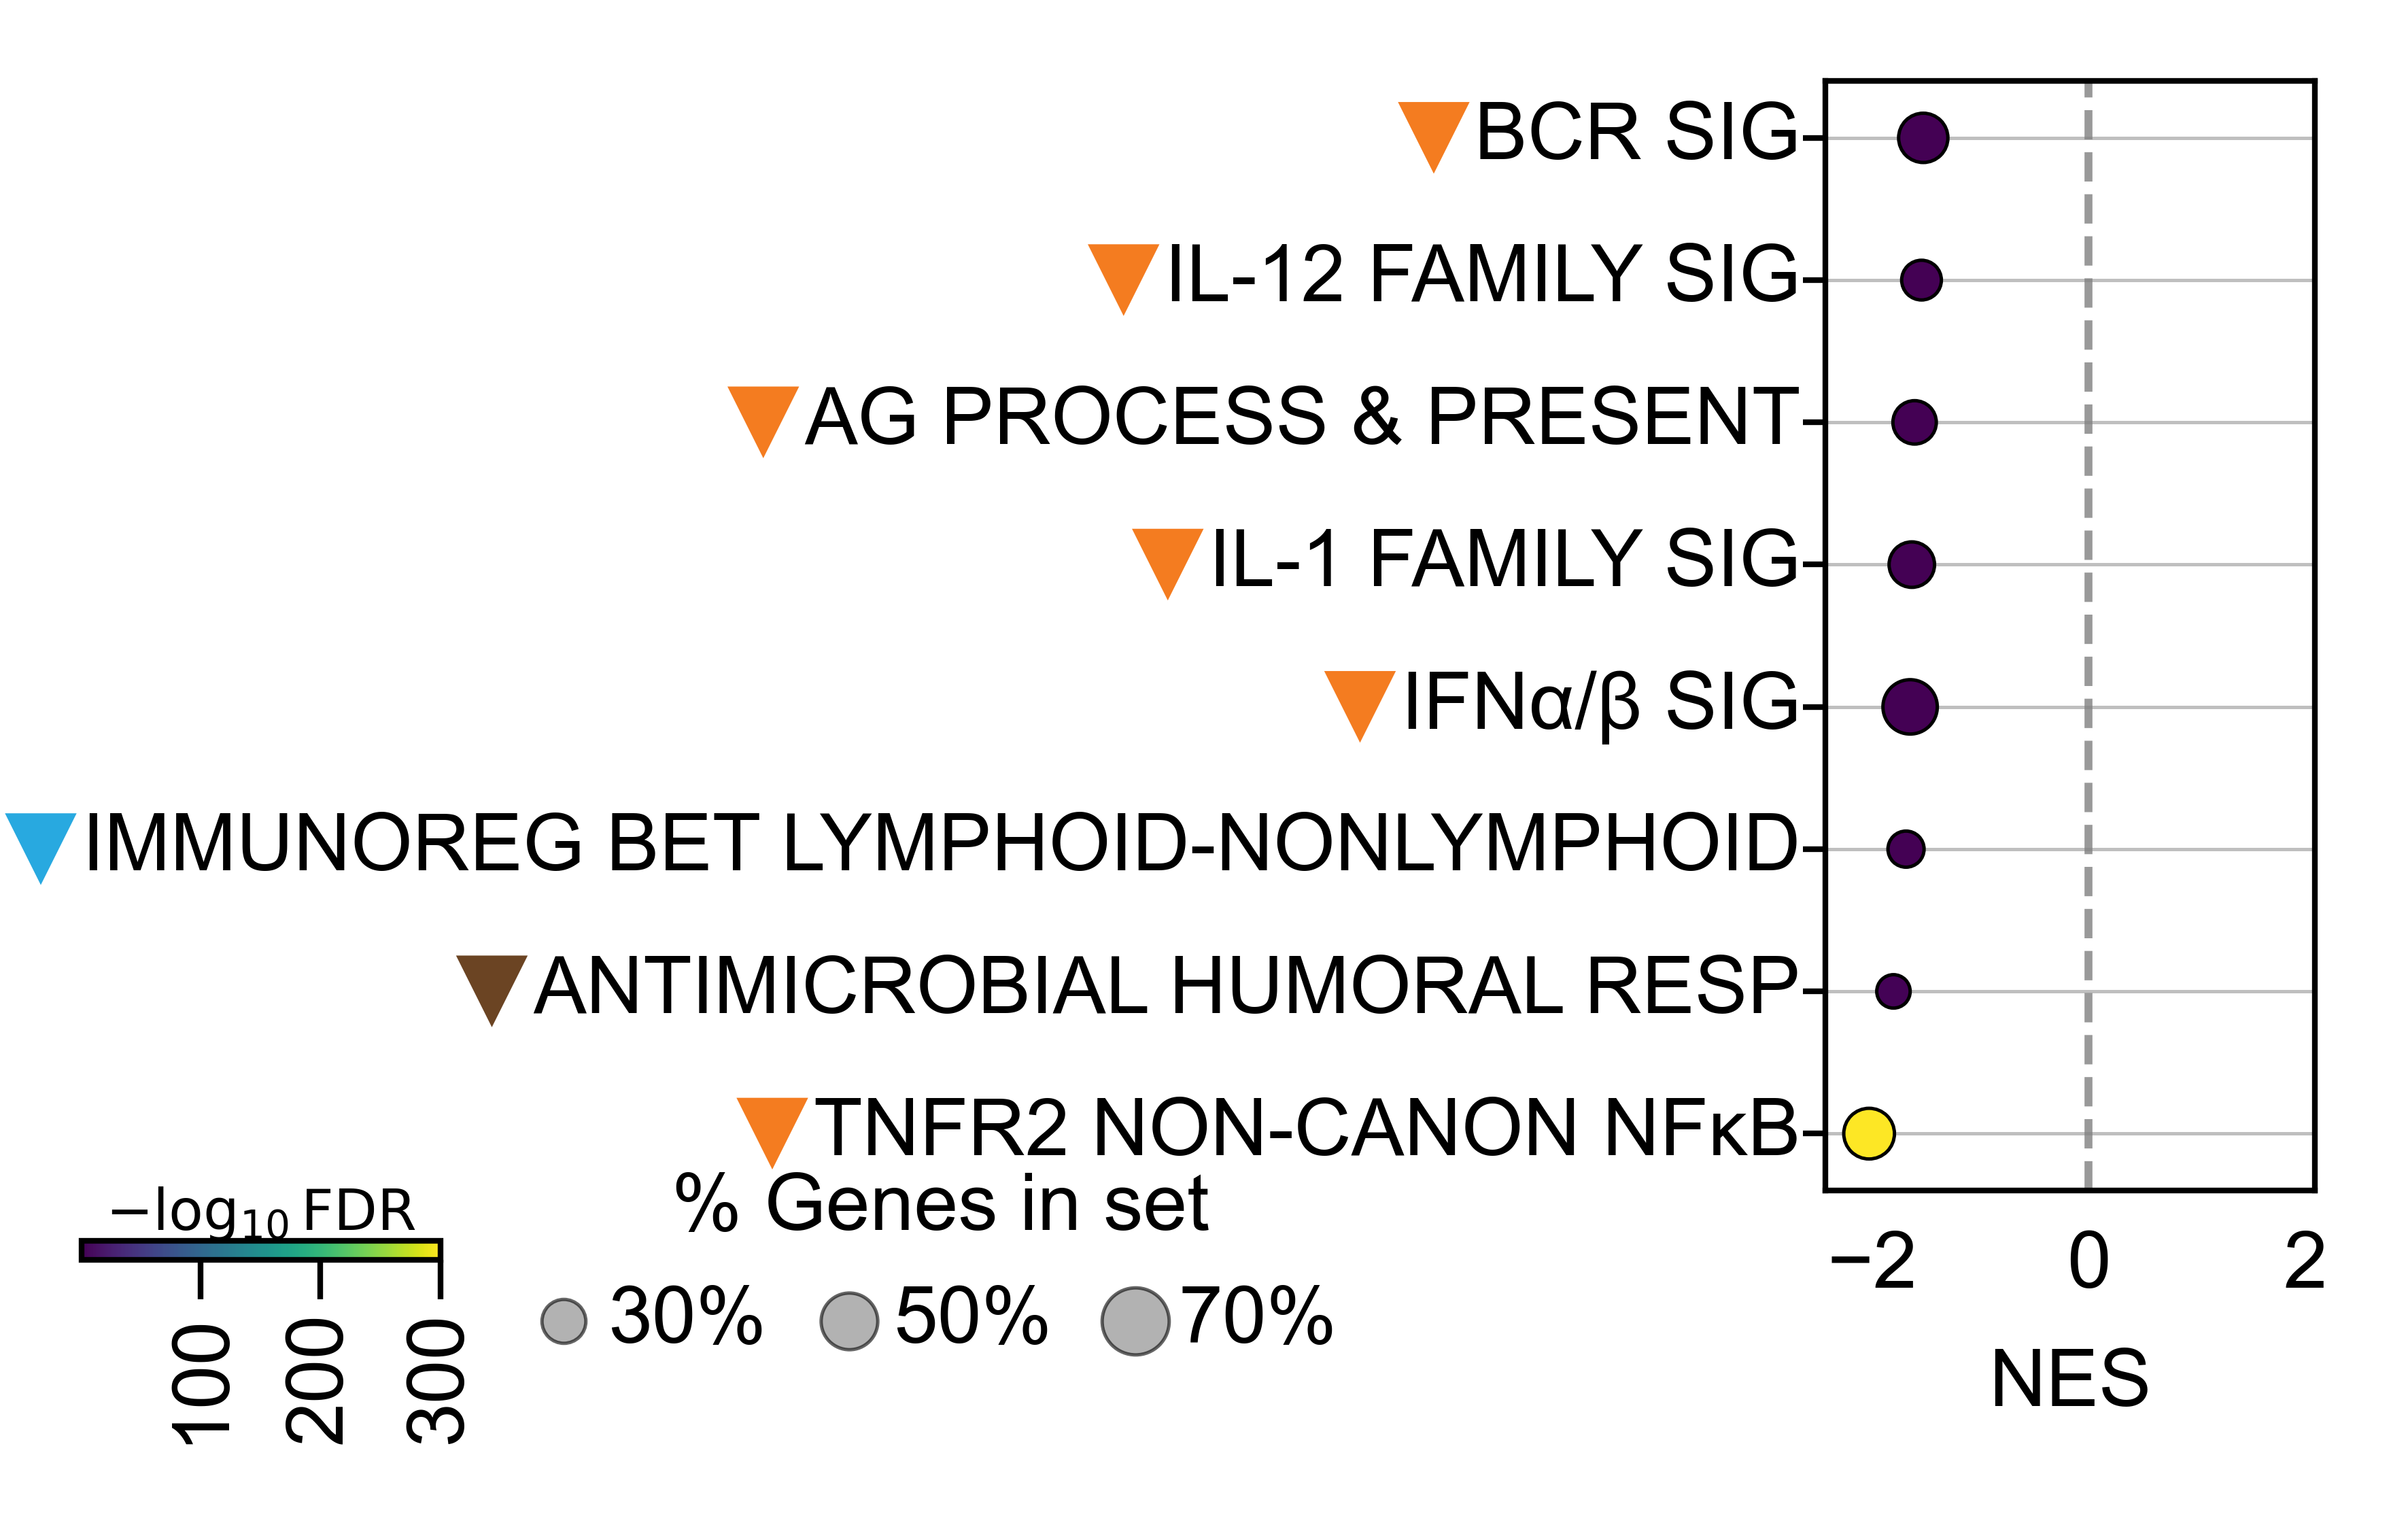

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill
from matplotlib import font_manager as fm

title_map = {"HRL": "High-Risk Lesion", "DCIS": "DCIS", "BC": "Breast Cancer"}

# -----------------------------
# Prepare data
# -----------------------------
dfp2 = dfp[dfp["Term"].isin(paths_relevant)].copy()
dfp2["Term"] = pd.Categorical(dfp2["Term"], categories=paths_relevant, ordered=True)
dfp2 = dfp2.sort_values("Term").reset_index(drop=True)

dfp2["Term_full"] = dfp2["Term"].astype(str)
dfp2["Term_short"] = dfp2["Term_full"].map(short_name_map).fillna(dfp2["Term_full"])
dfp2["Term_plot"] = dfp2["Term_short"].apply(lambda x: fill(str(x), width=38))

# -----------------------------
# Parameters
# -----------------------------
dot_scale = 0.5
cmap = plt.cm.viridis
arial_font = fm.FontProperties(family="Arial")

label_fontsize = 7
label_right_x = -0.05

triangle_gap_px = 20
triangle_size = 40
triangle_half_width_px = 10

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(2, 2))

# Main control:
# larger left = wider ylabel region + narrower bubble box
fig.subplots_adjust(left=0.68, right=0.98, bottom=0.24, top=0.92)

ypos = list(range(len(dfp2)))

sc = ax.scatter(
    dfp2["NES"],
    ypos,
    s=dfp2["Tag %"] * dot_scale,
    c=dfp2["log_p"],
    cmap=cmap,
    edgecolor="black",
    linewidth=0.3,
    zorder=3
)

# -----------------------------
# Manual y labels
# -----------------------------
ax.set_yticks(ypos)
ax.set_yticklabels([])
ax.invert_yaxis()
# shrink top/bottom padding inside bubble box
y_pad = 0.4
ax.set_ylim(len(dfp2) - 1 + y_pad, -y_pad)


label_text_objects = []

for i, row in dfp2.iterrows():
    txt = ax.text(
        label_right_x,
        i,
        row["Term_plot"],
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=label_fontsize,
        clip_on=False
    )
    label_text_objects.append((txt, row["Term_full"], i))

# -----------------------------
# Axes formatting
# -----------------------------
nes_max = dfp2["NES"].abs().max()
nes_min = dfp2["NES"].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.03])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", length=2, labelsize=6, pad=1)
ax.set_title('')#(title_map.get(DzState, DzState), fontsize=10, pad=8)

ax.grid(axis="y", linestyle="-", linewidth=0.3, color="gray", alpha=0.5, zorder=0)
ax.axvline(x=0, linestyle="--", linewidth=0.7, color="gray", alpha=0.8, zorder=1)

# -----------------------------
# Draw once, then measure manual labels
# -----------------------------
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

label_bboxes = [
    txt.get_window_extent(renderer=renderer)
    for txt, term_full, i in label_text_objects
]

leftmost_label_x_display = min(b.x0 for b in label_bboxes)
lowest_label_y_display = min(b.y0 for b in label_bboxes)

leftmost_label_x_fig, lowest_label_y_fig = fig.transFigure.inverted().transform(
    (leftmost_label_x_display, lowest_label_y_display)
)

# -----------------------------
# Triangles immediately left of labels
# -----------------------------
for txt, term_full, i in label_text_objects:
    tri = triangle_map.get(term_full)
    if tri is None:
        continue

    bbox = txt.get_window_extent(renderer=renderer)
    triangle_x_display = bbox.x0 - triangle_gap_px - triangle_half_width_px
    triangle_x_axes = ax.transAxes.inverted().transform((triangle_x_display, bbox.y0))[0]

    ax.scatter(
        triangle_x_axes,
        i,
        marker=tri["marker"],
        s=triangle_size,
        color=tri["color"],
        edgecolor="none",
        transform=ax.get_yaxis_transform(),
        clip_on=False,
        zorder=5
    )

# -----------------------------
# Colorbar: left aligned to leftmost ylabel
# -----------------------------
cbar_left = leftmost_label_x_fig
cbar_bottom = lowest_label_y_fig - 0.055
cbar_width = 0.22
cbar_height = 0.012

cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])

cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
cbar.set_label(
    r"$-\log_{10}\mathrm{FDR}$",
    fontproperties=arial_font,
    fontsize=5,
    labelpad=1
)
cbar.ax.xaxis.set_label_position("top")
cbar.ax.xaxis.set_ticks_position("bottom")
cbar.ax.tick_params(labelsize=7, pad=1, rotation=90)
cbar.solids.set_rasterized(True)

# -----------------------------
# Bubble legend: right of colorbar
# -----------------------------
size_handles = [
    plt.scatter(
        [], [],
        s=size * dot_scale,
        c="gray",
        alpha=0.6,
        edgecolor="black",
        linewidth=0.3
    )
    for size in [30, 50, 70]
]

bubble_legend_x = cbar_left + cbar_width * 1.2
bubble_legend_y = cbar_bottom - 0.003

leg = fig.legend(
    size_handles,
    ["30%", "50%", "70%"],
    title="% Genes in set",
    title_fontsize=7,
    fontsize=7,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(bubble_legend_x, bubble_legend_y),
    ncol=3,
    columnspacing=0.8,
    handletextpad=0.3,
    borderaxespad=0
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    f"plots/F6/Bubble_B_{DzState}.png",
    bbox_inches="tight",
    pad_inches=0.2, 
    dpi=600
)

plt.show()

### BC

In [17]:
DzState, db = 'BC', 'immport'
qthres=.1


dfp = out[
    (out['analysis_group']==DzState) &
    (out['analysis_db']==db) &
    (out['FDR q-val']<qthres)
    ]

dfp['Term'].unique()

array(['TOLERANCE INDUCTION', 'ALPHA-BETA T CELL ACTIVATION',
       'T CELL DIFFERENTIATION',
       'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
       'ANTIMICROBIAL PEPTIDES', 'INTERLEUKIN-12 FAMILY SIGNALING',
       'INTERFERON ALPHA/BETA SIGNALING',
       'C-TYPE LECTIN RECEPTORS (CLRS)', 'MYELOID CELL HOMEOSTASIS',
       'CYTOSOLIC SENSORS OF PATHOGEN-ASSOCIATED DNA ',
       'ANTIMICROBIAL HUMORAL RESPONSE',
       'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
       'ALPHA-PROTEIN KINASE 1 SIGNALING PATHWAY',
       'MHC CLASS II ANTIGEN PRESENTATION',
       'SIGNALING BY THE B CELL RECEPTOR (BCR)', 'TCR SIGNALING',
       'INTERFERON GAMMA SIGNALING',
       'ROS AND RNS PRODUCTION IN PHAGOCYTES',
       'INTERLEUKIN-1 FAMILY SIGNALING',
       'INNATE IMMUNE RESPONSE IN MUCOSA', 'NEUTROPHIL DEGRANULATION',
       'ANTIGEN PROCESSING AND PRESENTATION',
       'TNFR2 NON-CANONICAL NF-KB PATHWAY'], dtype=object)

In [18]:
paths_relevant = [
'TOLERANCE INDUCTION', 
# 'ALPHA-BETA T CELL ACTIVATION',
# 'T CELL DIFFERENTIATION',
# 'NEGATIVE REGULATION OF TOLL-LIKE RECEPTOR 2 SIGNALING PATHWAY',
'ANTIMICROBIAL PEPTIDES', 
'INTERLEUKIN-12 FAMILY SIGNALING',
'INTERFERON ALPHA/BETA SIGNALING',
# 'C-TYPE LECTIN RECEPTORS (CLRS)', 
# 'MYELOID CELL HOMEOSTASIS',
# 'CYTOSOLIC SENSORS OF PATHOGEN-ASSOCIATED DNA ',
'ANTIMICROBIAL HUMORAL RESPONSE',
# 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE',
# 'ALPHA-PROTEIN KINASE 1 SIGNALING PATHWAY',
'MHC CLASS II ANTIGEN PRESENTATION',
'SIGNALING BY THE B CELL RECEPTOR (BCR)', 
    # 'TCR SIGNALING',
'INTERFERON GAMMA SIGNALING',
'ROS AND RNS PRODUCTION IN PHAGOCYTES',
'INTERLEUKIN-1 FAMILY SIGNALING',
# 'INNATE IMMUNE RESPONSE IN MUCOSA', 
    # 'NEUTROPHIL DEGRANULATION',
'ANTIGEN PROCESSING AND PRESENTATION',
'TNFR2 NON-CANONICAL NF-KB PATHWAY'    
]

In [19]:
dfp_sel = dfp[dfp['Term'].isin(paths_relevant)]
dfp_sel.to_csv(f'data/Tables/B_{DzState}.csv')

In [51]:
short_name_map = {
    'TOLERANCE INDUCTION': 'TOLERANCE INDUCTION',
    'ANTIMICROBIAL PEPTIDES': 'ANTIMICROBIAL PEPTIDES',
    'INTERLEUKIN-12 FAMILY SIGNALING': 'IL-12 FAMILY SIG',
    'INTERFERON ALPHA/BETA SIGNALING': 'IFNα/β SIG',
    'ANTIMICROBIAL HUMORAL RESPONSE': 'ANTIMICROBIAL HUMORAL RESP',
    # 'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE': 'TISSUE-SPECIFIC IMMUNITY',
    'MHC CLASS II ANTIGEN PRESENTATION': 'MHC II AG PRESENT',
    'SIGNALING BY THE B CELL RECEPTOR (BCR)': 'BCR SIG',
    'INTERFERON GAMMA SIGNALING': 'IFNγ SIG',
    'ROS AND RNS PRODUCTION IN PHAGOCYTES': 'PHAGOCYTE ROS/RNS',
    'INTERLEUKIN-1 FAMILY SIGNALING': 'IL-1 FAMILY SIG',
    # 'INNATE IMMUNE RESPONSE IN MUCOSA': 'MUCOSAL INNATE IMMUNITY',
    'ANTIGEN PROCESSING AND PRESENTATION': 'AG PROCESS & PRESENT',
    'TNFR2 NON-CANONICAL NF-KB PATHWAY': 'TNFR2 NON-CANON NFκB',
}

In [53]:
triangle_map = {
    'TOLERANCE INDUCTION':
        {"marker": "^", "color": "#28A9E0"},  # blue; Regulation / tolerance
    'ANTIMICROBIAL PEPTIDES':
        {"marker": "^", "color": "#6B4423"},  # brown; Innate-like immune response
    'INTERLEUKIN-12 FAMILY SIGNALING':
        {"marker": "v", "color": "#F47C20"},  # orange; Activation / inflammatory signaling
    'INTERFERON ALPHA/BETA SIGNALING':
        {"marker": "v", "color": "#F47C20"},  # orange; Activation / inflammatory signaling
    'ANTIMICROBIAL HUMORAL RESPONSE':
        {"marker": "v", "color": "#6B4423"},  # brown; Innate-like immune response
    'ORGAN OR TISSUE SPECIFIC IMMUNE RESPONSE':
        {"marker": "v", "color": "#6B4423"},  # brown; Innate-like immune response
    'MHC CLASS II ANTIGEN PRESENTATION':
        {"marker": "v", "color": "#6B4423"},  # brown; Innate-like immune response / antigen presentation
    'SIGNALING BY THE B CELL RECEPTOR (BCR)':
        {"marker": "v", "color": "#F47C20"},  # orange; Activation / inflammatory signaling
    'INTERFERON GAMMA SIGNALING':
        {"marker": "v", "color": "#F47C20"},  # orange; Activation / inflammatory signaling
    'ROS AND RNS PRODUCTION IN PHAGOCYTES':
        {"marker": "v", "color": "#F47C20"},  # orange; Activation / inflammatory signaling
    'INTERLEUKIN-1 FAMILY SIGNALING':
        {"marker": "v", "color": "#F47C20"},  # orange; Activation / inflammatory signaling
    'INNATE IMMUNE RESPONSE IN MUCOSA':
        {"marker": "v", "color": "#6B4423"},  # brown; Innate-like immune response
    'ANTIGEN PROCESSING AND PRESENTATION':
        {"marker": "v", "color": "#6B4423"},  # brown; Innate-like immune response / antigen presentation
    'TNFR2 NON-CANONICAL NF-KB PATHWAY':
        {"marker": "v", "color": "#F47C20"},  # orange; Activation / inflammatory signaling
}

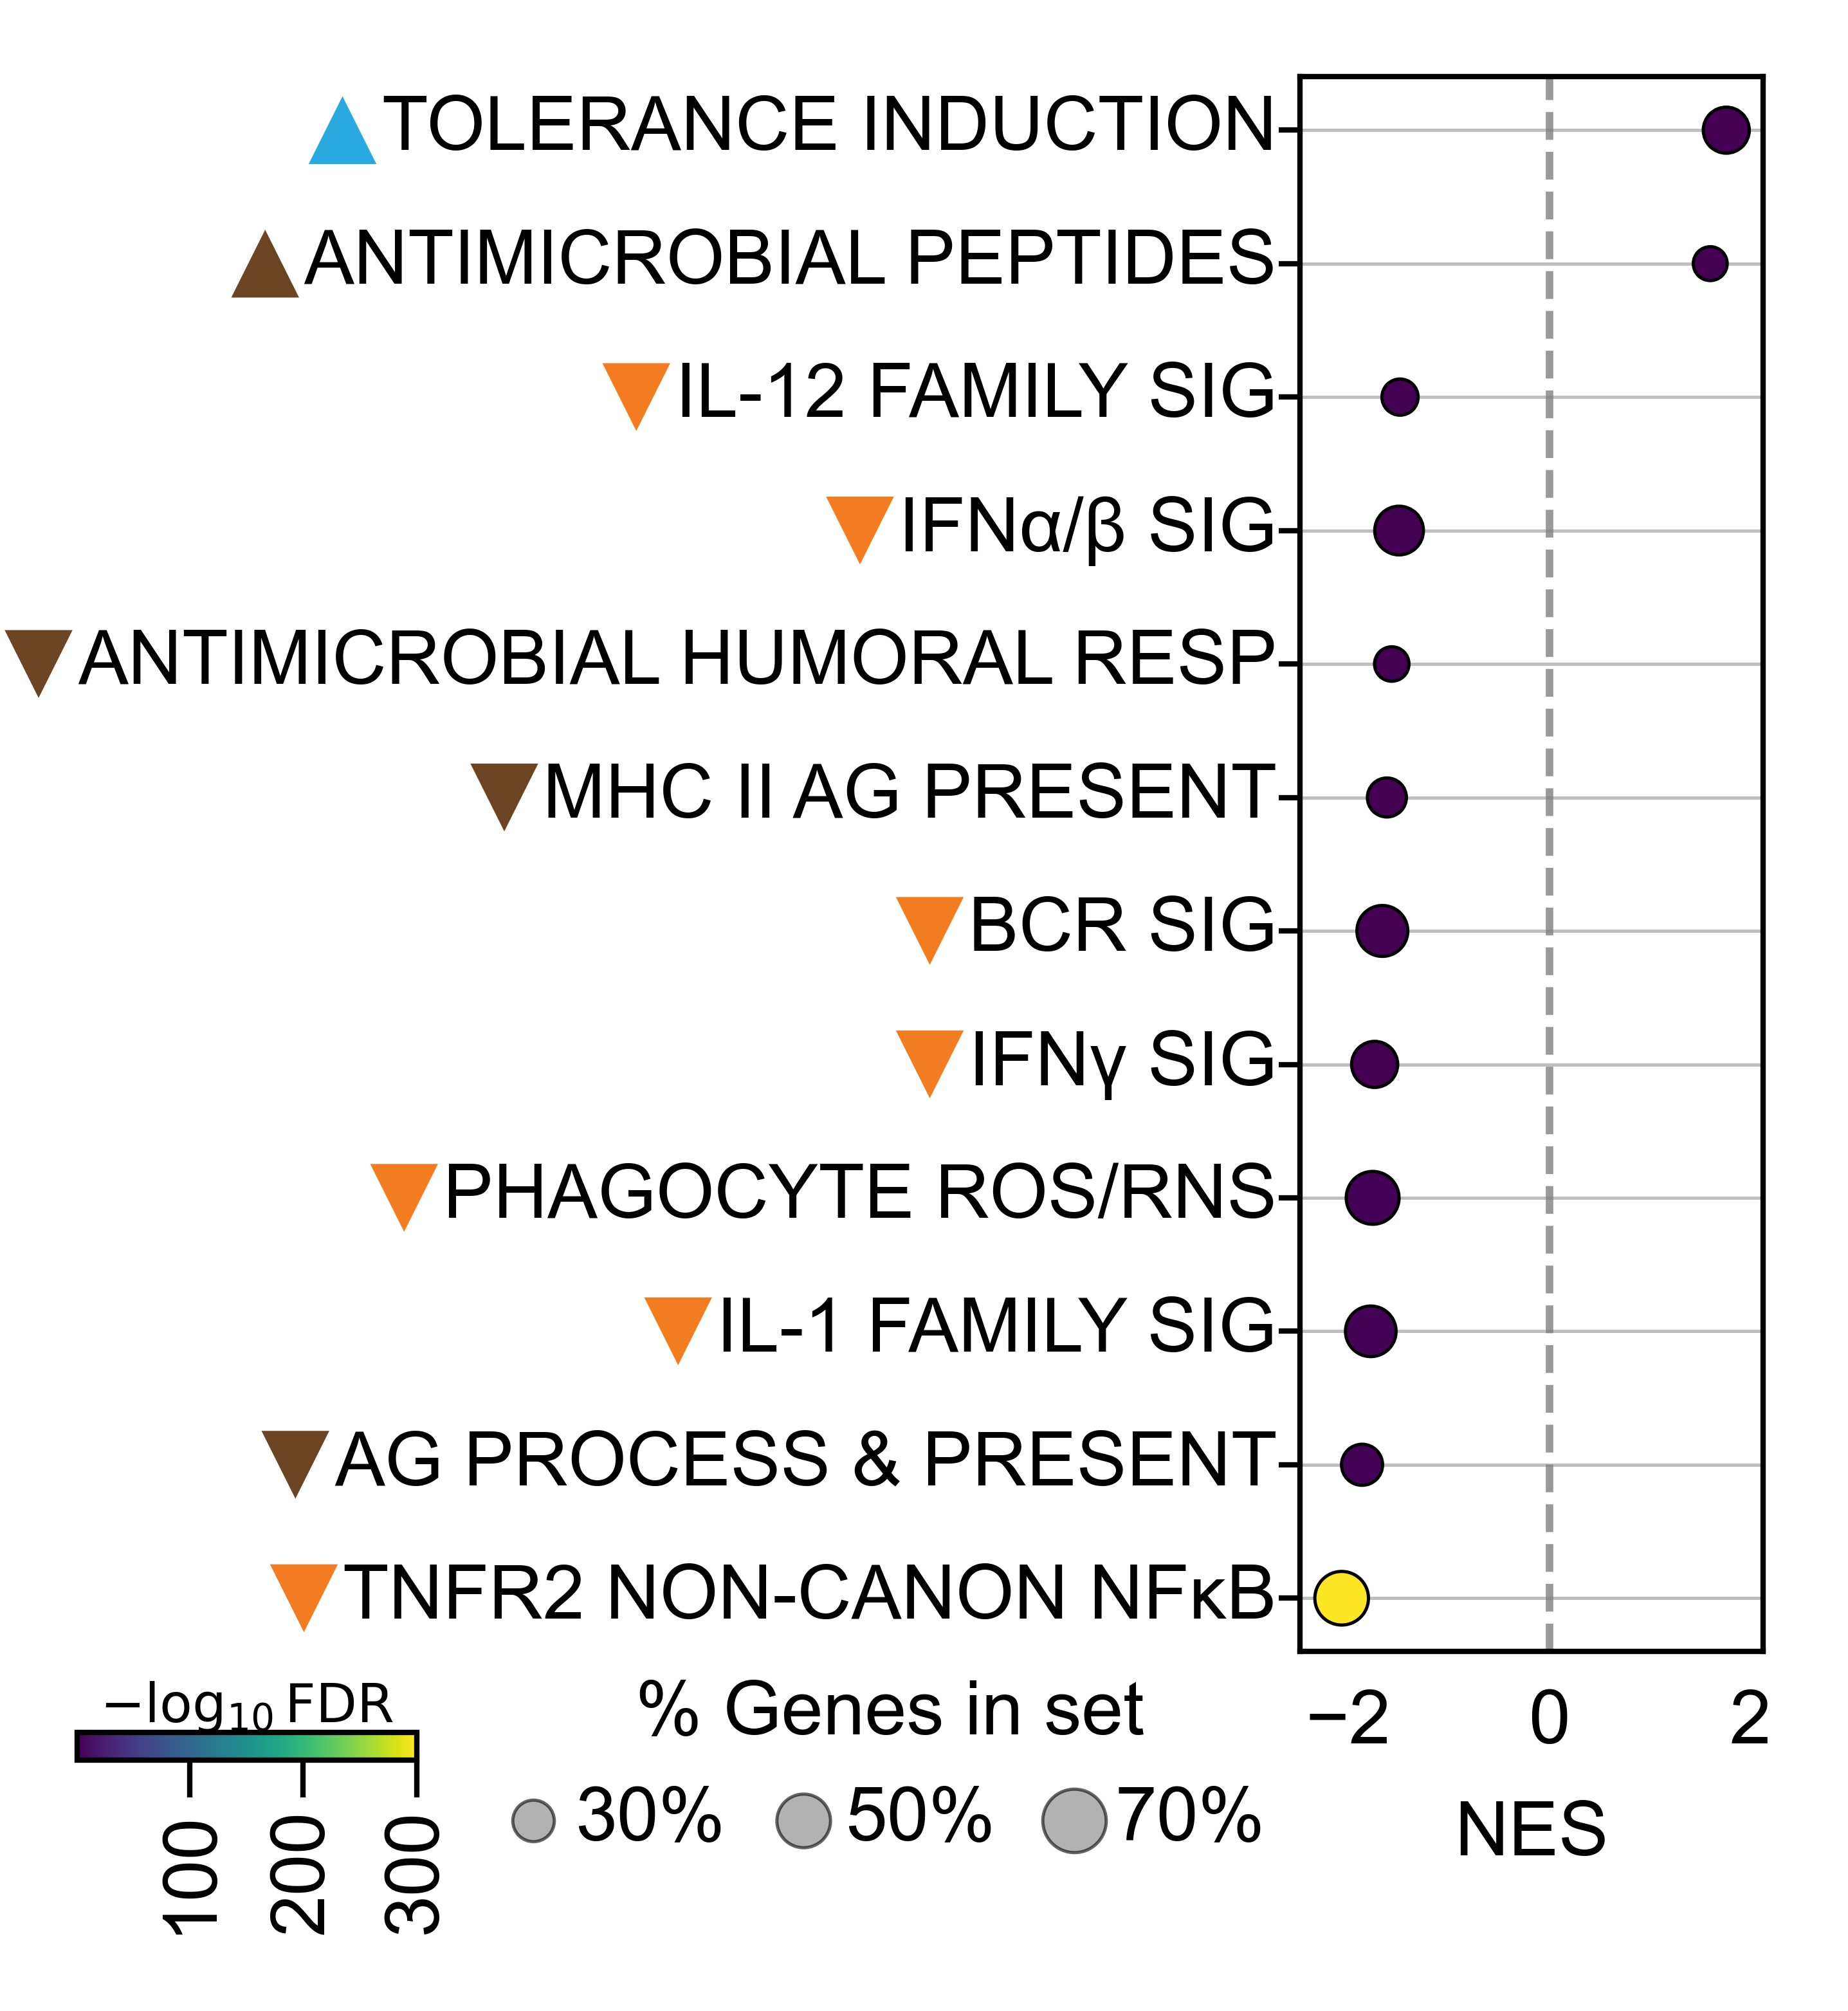

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
from textwrap import fill
from matplotlib import font_manager as fm

title_map = {"HRL": "High-Risk Lesion", "DCIS": "DCIS", "BC": "Breast Cancer"}

# -----------------------------
# Prepare data
# -----------------------------
dfp2 = dfp[dfp["Term"].isin(paths_relevant)].copy()
dfp2["Term"] = pd.Categorical(dfp2["Term"], categories=paths_relevant, ordered=True)
dfp2 = dfp2.sort_values("Term").reset_index(drop=True)

dfp2["Term_full"] = dfp2["Term"].astype(str)
dfp2["Term_short"] = dfp2["Term_full"].map(short_name_map).fillna(dfp2["Term_full"])
dfp2["Term_plot"] = dfp2["Term_short"].apply(lambda x: fill(str(x), width=38))

# -----------------------------
# Parameters
# -----------------------------
dot_scale = 0.5
cmap = plt.cm.viridis
arial_font = fm.FontProperties(family="Arial")

label_fontsize = 7
label_right_x = -0.05

triangle_gap_px = 20
triangle_size = 40
triangle_half_width_px = 10

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(2, 3))

# Main control:
# larger left = wider ylabel region + narrower bubble box
fig.subplots_adjust(left=0.68, right=0.98, bottom=0.24, top=0.92)

ypos = list(range(len(dfp2)))

sc = ax.scatter(
    dfp2["NES"],
    ypos,
    s=dfp2["Tag %"] * dot_scale,
    c=dfp2["log_p"],
    cmap=cmap,
    edgecolor="black",
    linewidth=0.3,
    zorder=3
)

# -----------------------------
# Manual y labels
# -----------------------------
ax.set_yticks(ypos)
ax.set_yticklabels([])
ax.invert_yaxis()
# shrink top/bottom padding inside bubble box
y_pad = 0.4
ax.set_ylim(len(dfp2) - 1 + y_pad, -y_pad)


label_text_objects = []

for i, row in dfp2.iterrows():
    txt = ax.text(
        label_right_x,
        i,
        row["Term_plot"],
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=label_fontsize,
        clip_on=False
    )
    label_text_objects.append((txt, row["Term_full"], i))

# -----------------------------
# Axes formatting
# -----------------------------
nes_max = dfp2["NES"].abs().max()
nes_min = dfp2["NES"].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.03])

ax.set_xlabel("NES", fontsize=7)
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", length=2, labelsize=6, pad=1)
ax.set_title('')#(title_map.get(DzState, DzState), fontsize=10, pad=8)

ax.grid(axis="y", linestyle="-", linewidth=0.3, color="gray", alpha=0.5, zorder=0)
ax.axvline(x=0, linestyle="--", linewidth=0.7, color="gray", alpha=0.8, zorder=1)

# -----------------------------
# Draw once, then measure manual labels
# -----------------------------
fig.canvas.draw()
renderer = fig.canvas.get_renderer()

label_bboxes = [
    txt.get_window_extent(renderer=renderer)
    for txt, term_full, i in label_text_objects
]

leftmost_label_x_display = min(b.x0 for b in label_bboxes)
lowest_label_y_display = min(b.y0 for b in label_bboxes)

leftmost_label_x_fig, lowest_label_y_fig = fig.transFigure.inverted().transform(
    (leftmost_label_x_display, lowest_label_y_display)
)

# -----------------------------
# Triangles immediately left of labels
# -----------------------------
for txt, term_full, i in label_text_objects:
    tri = triangle_map.get(term_full)
    if tri is None:
        continue

    bbox = txt.get_window_extent(renderer=renderer)
    triangle_x_display = bbox.x0 - triangle_gap_px - triangle_half_width_px
    triangle_x_axes = ax.transAxes.inverted().transform((triangle_x_display, bbox.y0))[0]

    ax.scatter(
        triangle_x_axes,
        i,
        marker=tri["marker"],
        s=triangle_size,
        color=tri["color"],
        edgecolor="none",
        transform=ax.get_yaxis_transform(),
        clip_on=False,
        zorder=5
    )

# -----------------------------
# Colorbar: left aligned to leftmost ylabel
# -----------------------------
cbar_left = leftmost_label_x_fig
cbar_bottom = lowest_label_y_fig - 0.055
cbar_width = 0.22
cbar_height = 0.012

cax = fig.add_axes([cbar_left, cbar_bottom, cbar_width, cbar_height])

cbar = fig.colorbar(sc, cax=cax, orientation="horizontal")
cbar.set_label(
    r"$-\log_{10}\mathrm{FDR}$",
    fontproperties=arial_font,
    fontsize=5,
    labelpad=1
)
cbar.ax.xaxis.set_label_position("top")
cbar.ax.xaxis.set_ticks_position("bottom")
cbar.ax.tick_params(labelsize=7, pad=1, rotation=90)
cbar.solids.set_rasterized(True)

# -----------------------------
# Bubble legend: right of colorbar
# -----------------------------
size_handles = [
    plt.scatter(
        [], [],
        s=size * dot_scale,
        c="gray",
        alpha=0.6,
        edgecolor="black",
        linewidth=0.3
    )
    for size in [30, 50, 70]
]

bubble_legend_x = cbar_left + cbar_width * 1.2
bubble_legend_y = cbar_bottom - 0.003

leg = fig.legend(
    size_handles,
    ["30%", "50%", "70%"],
    title="% Genes in set",
    title_fontsize=7,
    fontsize=7,
    frameon=False,
    loc="center left",
    bbox_to_anchor=(bubble_legend_x, bubble_legend_y),
    ncol=3,
    columnspacing=0.8,
    handletextpad=0.3,
    borderaxespad=0
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    f"plots/F6/Bubble_B_{DzState}.png",
    bbox_inches="tight",
    pad_inches=0.2, 
    dpi=600
)

plt.show()

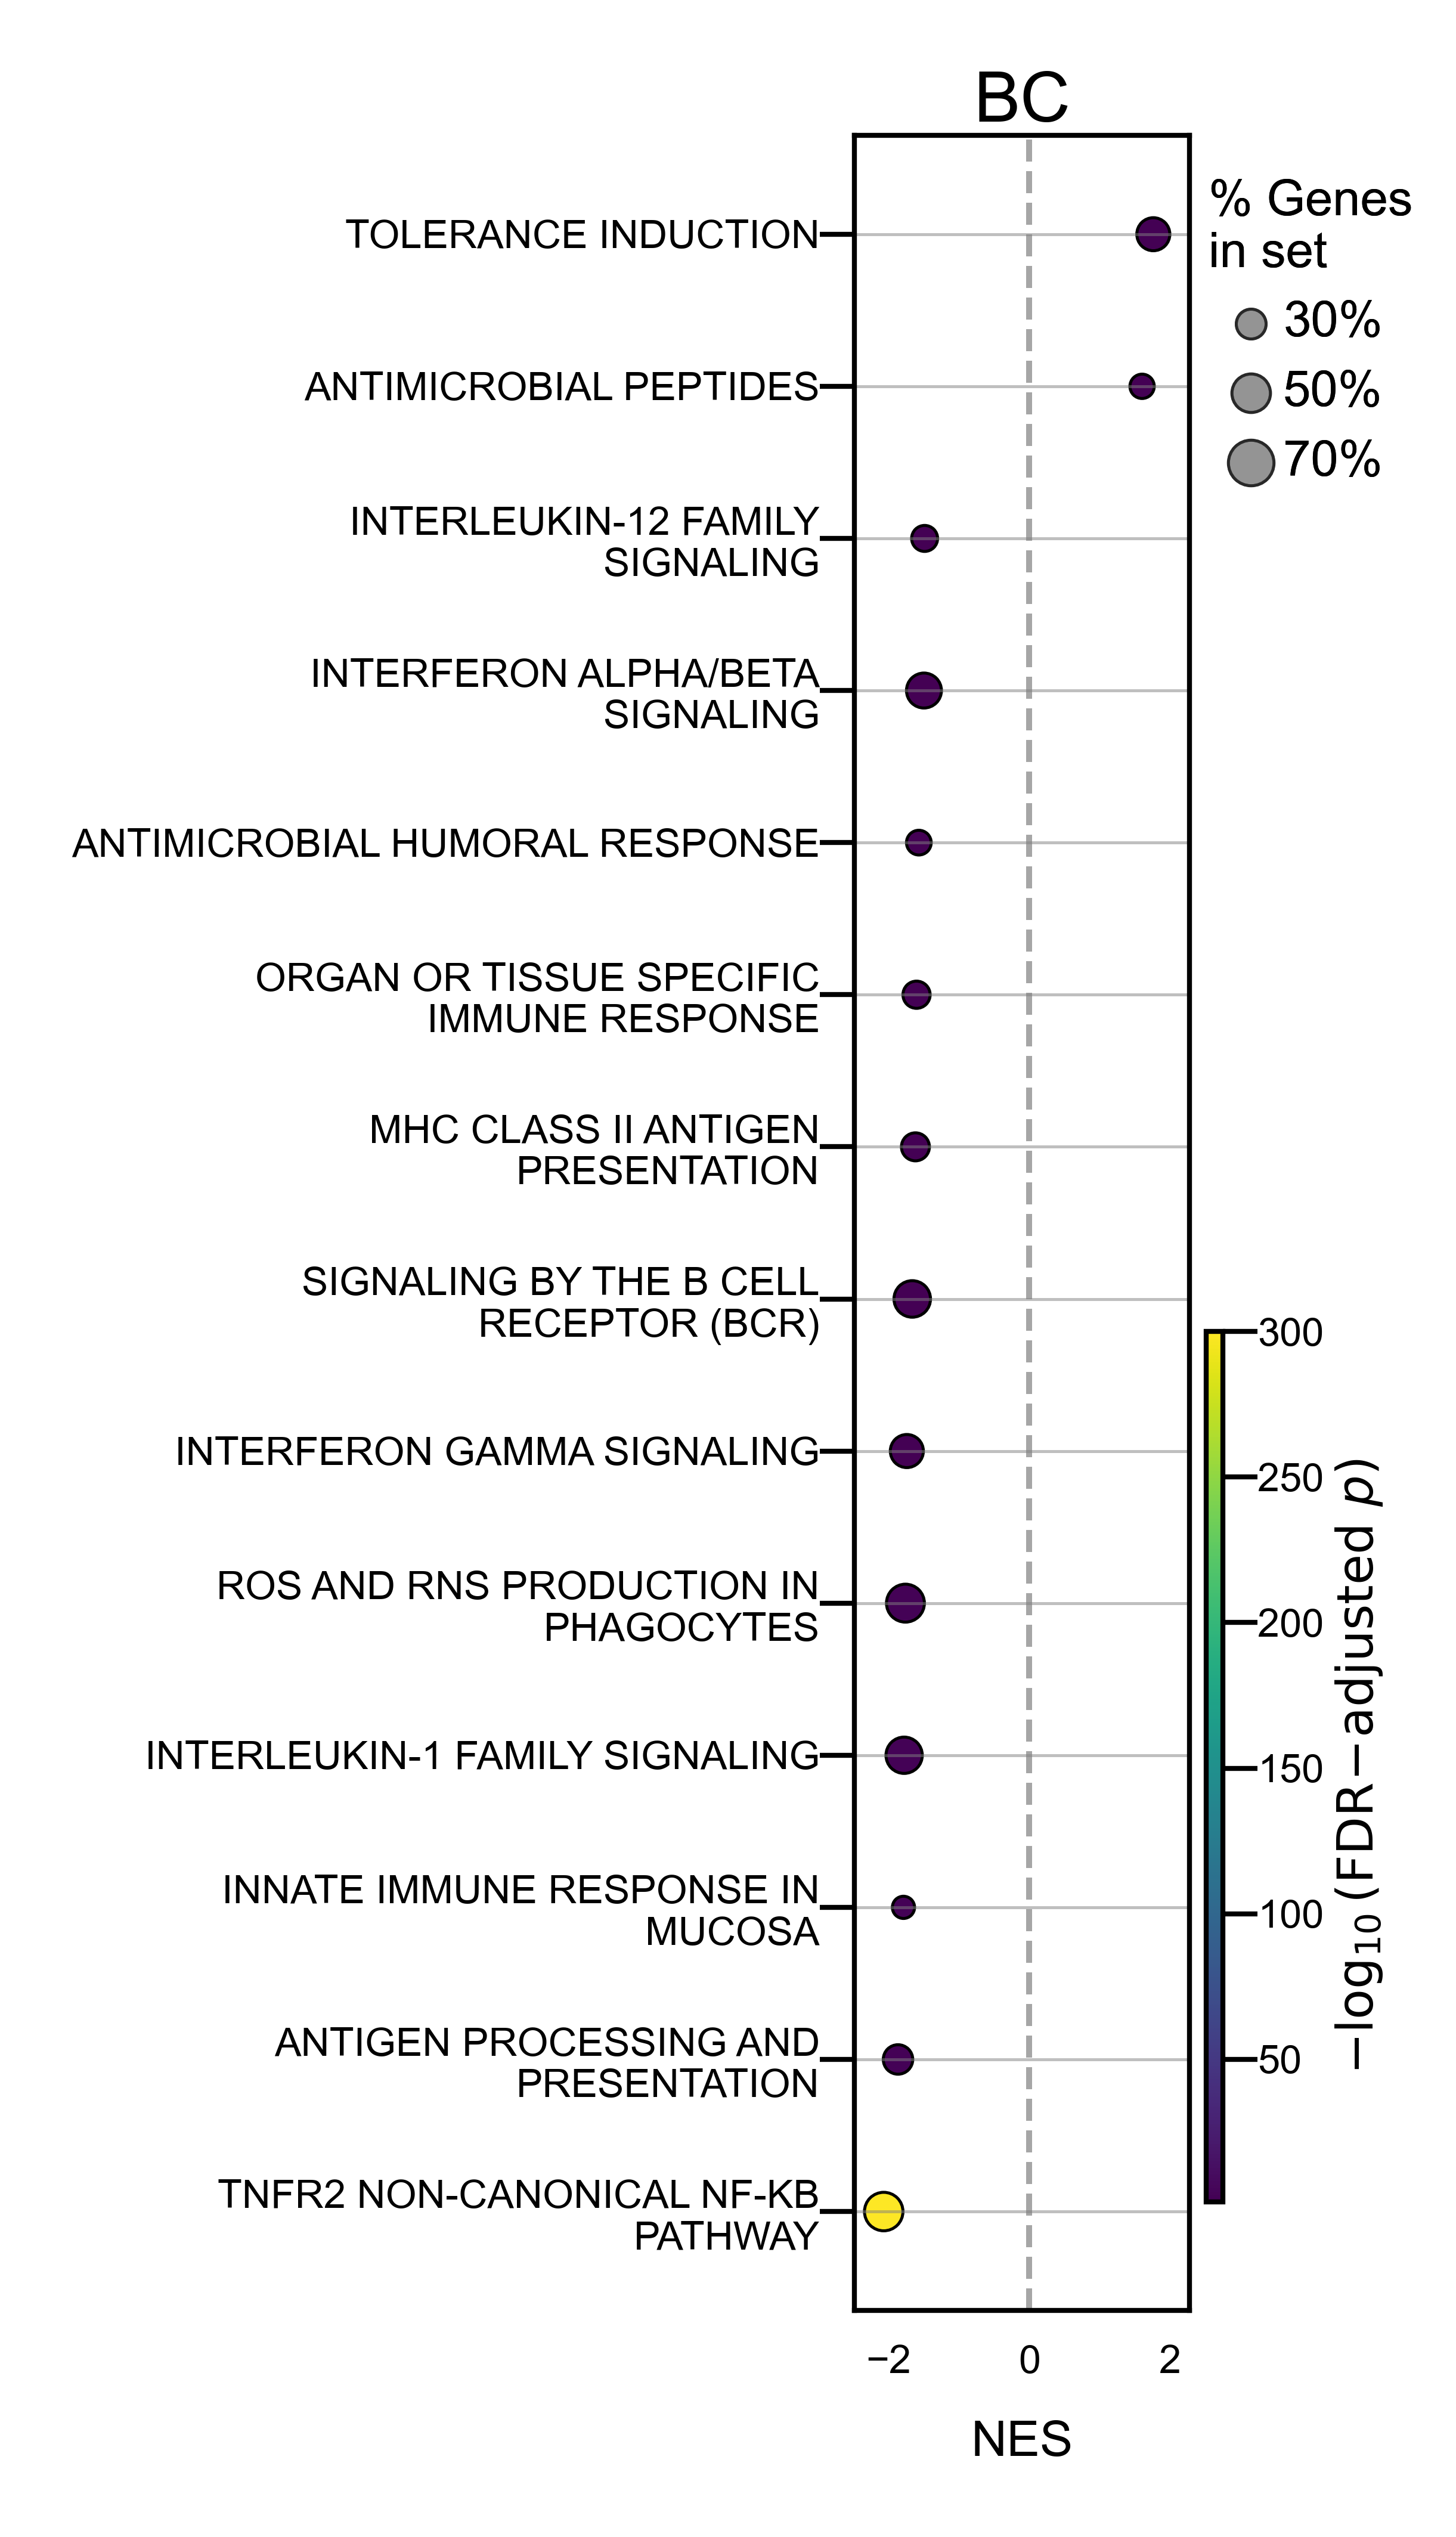

In [19]:
dfp2 = dfp[dfp['Term'].isin(paths_sel)].reset_index(drop=True)

wrap_width = 30
dfp2['Term'] = dfp2['Term'].apply(lambda x: fill(x, width=wrap_width))
# Parameters
dot_scale = .3   # smaller dot size multiplier
cmap = plt.cm.viridis


# Plot
fig, ax = plt.subplots(figsize=(.6
                                , 4))  # shorter height
sc = ax.scatter(
    dfp2['NES'],
    dfp2['Term'],
    s=dfp2['Tag %'] * dot_scale,    # dot size
    c=dfp2['log_p'],
    cmap=cmap,
    edgecolor='black',
    linewidth=0.3
)

# Reverse y-axis order
ax.invert_yaxis()


# Axis labels & ticks
nes_max = dfp2['NES'].abs().max()
pad = nes_max * 0.01
nes_min = dfp2['NES'].min()
ax.set_xlim([nes_min * 1.2, nes_max * 1.1])

ax.set_xlabel("NES", fontsize=5)
ax.set_ylabel("")
ax.tick_params(axis='x', labelsize=4)
ax.tick_params(axis='y', labelsize=4)
ax.set_title(DzState, fontsize=7, pad=-3)

# Horizontal gridlines
ax.grid(axis='y', linestyle='-', linewidth=0.3, color='gray', alpha=0.5)

# Colorbar legend
axins = inset_axes(ax,
                   width="5%",    # width relative to main ax
                   height="40%",  # shorter height
                   loc='lower right',
                   bbox_to_anchor=(0.1, 0.05, 1, 1),
                   bbox_transform=ax.transAxes,
                   borderpad=0)

cbar = fig.colorbar(sc, cax=axins)
from matplotlib import font_manager as fm
arial_font = fm.FontProperties(family='Arial')
cbar.set_label(r"$-\log_{10}(\mathrm{FDR\!-\!adjusted\ }p)$", fontproperties=arial_font,   fontsize=5, labelpad=1)
cbar.ax.tick_params(labelsize=4)
cbar.solids.set_rasterized(True)  # <-- fixes blank SVG colorbar

# Size legend
for size in [30, 50, 70]:  # example % values
    ax.scatter([], [], s=size*dot_scale, c='gray', alpha=0.6, edgecolor='black', linewidth=0.3,
               label=f"{size}%")
leg1 = ax.legend(
    title="% Genes\nin set", title_fontsize=5, frameon=False,
    fontsize=5, loc='upper right', bbox_to_anchor=(1.8, 1)
)
ax.add_artist(leg1)
ax.axvline(
    x=0,
    linestyle='--',
    linewidth=0.6,
    color='gray',
    alpha=0.7,
    zorder=0
)
# plt.tight_layout()
plt.savefig(f"plots/S6/Bubble_B_{DzState}_{db}.svg", 
            # dpi=600, 
            bbox_inches='tight'
            )